# LAB 2 — Extraction of Latent Features using CNN for Image Datasets

**AIM:** To understand the process of extracting features from images using Convolutional Neural Networks (CNN) and apply CNN models for image classification by analysing the effect of different hyperparameters.

## Imports

In [58]:
# !pip install torch torchvision matplotlib pillow numpy

import os, time, math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T

torch.manual_seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100
print("PyTorch:", torch.__version__)

PyTorch: 2.14.0


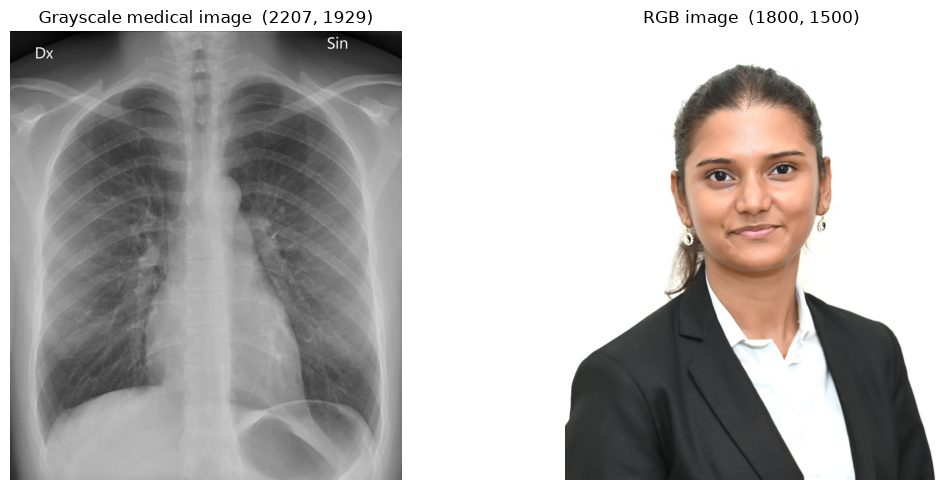

In [59]:
# ---- Image files --------------------------------------------------------
GRAY_PATH = "/Users/22sarthak/AMI/grayscale.jpg"
RGB_PATH  = "/Users/22sarthak/AMI/NANDINI.jpg"

for p in [GRAY_PATH, RGB_PATH]:
    assert os.path.exists(p), f"File not found: {p}"

gray_img = Image.open(GRAY_PATH).convert("L")
rgb_img  = Image.open(RGB_PATH).convert("RGB")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(gray_img, cmap="gray")
ax[0].set_title(f"Grayscale medical image  {gray_img.size[::-1]}")
ax[1].imshow(rgb_img)
ax[1].set_title(f"RGB image  {rgb_img.size[::-1]}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Inference:** The two inputs differ in structure: the X-ray is a **single-channel** intensity image (2207×1929) where bright = dense tissue (bone, heart) and dark = air (lungs); the portrait is a **3-channel** colour image (1800×1500) with a plain white background, so most of its information sits in the face, hair and blazer.

### Helper functions (used for every visualisation in the notebook)

In [60]:
def to_np(t):
    return t.detach().cpu().numpy() if torch.is_tensor(t) else np.asarray(t)

def show_feature_maps(fmap, title, max_maps=16, cols=8, cmap="viridis"):
    # fmap: tensor of shape (1, C, H, W) or (C, H, W). Shows up to max_maps channels.
    fmap = to_np(fmap)
    if fmap.ndim == 4:
        fmap = fmap[0]
    C, H, W = fmap.shape
    n = min(C, max_maps)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.7, rows * 1.8))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            ax.imshow(fmap[i], cmap=cmap)
            ax.set_title(f"ch {i}", fontsize=8)
    fig.suptitle(f"{title}   |   shape = ({C}, {H}, {W})  (showing {n}/{C})", fontsize=11)
    plt.tight_layout()
    plt.show()

def show_vector(vec, title, heat_cols=None):
    # 1-D feature vector as a bar plot + (optionally) a 2-D heatmap.
    v = to_np(vec).reshape(-1)
    ncols = 2 if heat_cols else 1
    fig, axes = plt.subplots(1, ncols, figsize=(14 if heat_cols else 12, 3))
    axes = np.atleast_1d(axes)
    axes[0].bar(np.arange(len(v)), v, width=1.0)
    axes[0].set_xlabel("feature index"); axes[0].set_ylabel("value")
    axes[0].set_title(f"{title}  (length = {len(v)})")
    if heat_cols:
        rows = math.ceil(len(v) / heat_cols)
        pad = np.zeros(rows * heat_cols); pad[:len(v)] = v
        im = axes[1].imshow(pad.reshape(rows, heat_cols), cmap="magma", aspect="auto")
        axes[1].set_title(f"{title} as {rows}×{heat_cols} heatmap")
        plt.colorbar(im, ax=axes[1])
    plt.tight_layout(); plt.show()
    print(f"min={v.min():.4f}  max={v.max():.4f}  mean={v.mean():.4f}  "
          f"non-zero={np.count_nonzero(v)}/{len(v)}")

def show_kernels(kernels, names, title):
    n = len(kernels)
    fig, axes = plt.subplots(1, n, figsize=(n * 1.8, 2.1))
    for ax, k, nm in zip(np.atleast_1d(axes), kernels, names):
        ax.imshow(k, cmap="coolwarm"); ax.set_title(nm, fontsize=8); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

def register_hooks(model):
    # Stores the output of every named leaf layer in model.activations
    model.activations = {}
    handles = []
    for name, layer in model.named_modules():
        if len(list(layer.children())) == 0 and name:
            def hook(m, inp, out, name=name):
                model.activations[name] = out.detach()
            handles.append(layer.register_forward_hook(hook))
    return handles

def model_summary(model, input_shape):
    # Prints layer-wise output shapes and parameter counts (like keras .summary()).
    rows = []
    def hook(m, i, o, name):
        p = sum(q.numel() for q in m.parameters(recurse=False))
        rows.append((name, m.__class__.__name__, tuple(o.shape), p))
    hs = [m.register_forward_hook(lambda m, i, o, n=n: hook(m, i, o, n))
          for n, m in model.named_modules() if len(list(m.children())) == 0 and n]
    with torch.no_grad():
        model(torch.zeros(1, *input_shape))
    for h in hs: h.remove()
    print(f"{'Layer':<14}{'Type':<12}{'Output shape':<22}{'Params':>10}")
    print("-" * 58)
    for n, t, s, p in rows:
        print(f"{n:<14}{t:<12}{str(s):<22}{p:>10,}")
    print("-" * 58)
    total = sum(p.numel() for p in model.parameters())
    print(f"Total trainable parameters: {total:,}")

# PART A — Grayscale Medical Image

**Question:** *Select any grayscale medical image dataset/image (e.g., X-ray, MRI, CT scan, ultrasound image).*

We use a **posteroanterior (PA) chest X-ray**. It is loaded in mode `"L"` (single-channel, 8-bit grayscale).

### A.0 — Visualise the original grayscale medical image

**Question:** *Extract and visualize: Original grayscale medical image.*

Original size (W×H): (1929, 2207) | mode: L | dtype: uint8 | range: 0 - 255


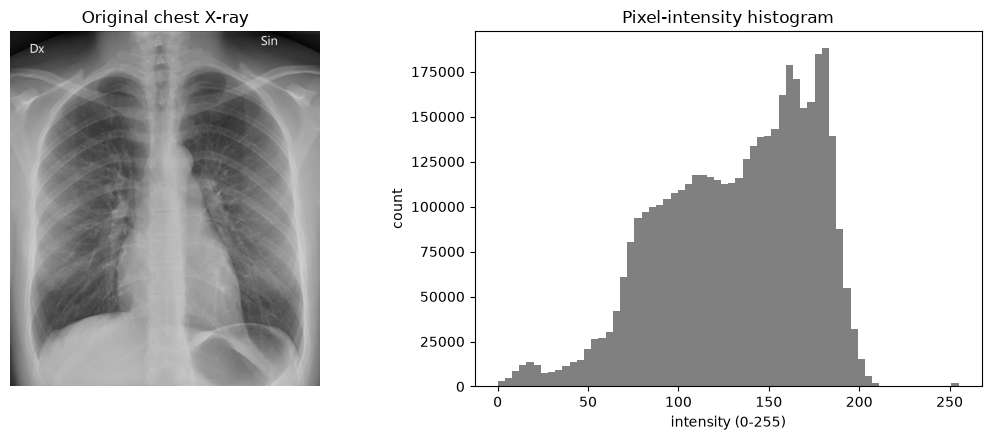

In [61]:
gray_pil = Image.open(GRAY_PATH).convert("L")
gray_np  = np.array(gray_pil)

print("Original size (W×H):", gray_pil.size, "| mode:", gray_pil.mode,
      "| dtype:", gray_np.dtype, "| range:", gray_np.min(), "-", gray_np.max())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(gray_np, cmap="gray"); ax[0].set_title("Original chest X-ray"); ax[0].axis("off")
ax[1].hist(gray_np.ravel(), bins=64, color="gray"); ax[1].set_title("Pixel-intensity histogram")
ax[1].set_xlabel("intensity (0-255)"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.show()

**Inference:** 
- The histogram is skewed towards the bright side (most pixels ≈ 100–190) with a thin dark tail — bones, heart and soft tissue dominate, while the dark lung fields form the lower peak. 
- The image uses almost the full 0–255 range, so it has good contrast for edge detection.

## A.1 — Input image pre-processing

**Question (a):** *Input image pre-processing:*
- *Resize the image into suitable dimensions.*
- *Normalize pixel intensity values.*
- *Convert image into tensor format.*

### A.1.1 Resize the image into suitable dimensions
A CNN needs a fixed input size. **128 × 128** keeps enough anatomical detail (ribs, lung fields, heart border) while keeping the computation (and the from-scratch convolution) fast.

Resized shape: (128, 128)


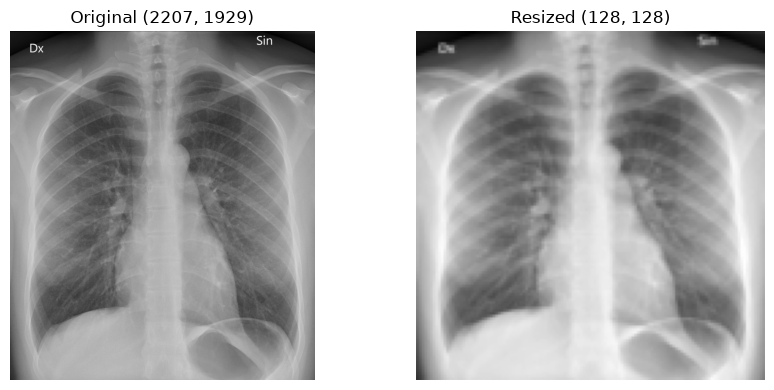

In [62]:
IMG_SIZE = 128
gray_resized = gray_pil.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
gray_resized_np = np.array(gray_resized).astype(np.float32)
print("Resized shape:", gray_resized_np.shape)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(gray_np, cmap="gray"); ax[0].set_title(f"Original {gray_np.shape}")
ax[1].imshow(gray_resized_np, cmap="gray"); ax[1].set_title(f"Resized {gray_resized_np.shape}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Inference:**
- Down-sampling 2207×1929 → 128×128 (≈ 260× fewer pixels) keeps the ribs, lung fields, heart shadow and diaphragm clearly visible. 
- Fine details (small vessels, the "Dx/Sin" markers) blur, which is acceptable for learning global features and makes computation fast. 
- The aspect ratio changes slightly (non-square → square).

### A.1.2 Normalize pixel intensity values
Two common normalisations:
1. **Min–max scaling** to $[0,1]$: $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$
2. **Z-score standardisation**: $x'' = \dfrac{x' - \mu}{\sigma}$ → zero mean, unit variance (helps gradient-based training).

raw             min=   2.000  max= 205.000  mean=132.292  std= 40.684
min-max [0,1]   min=   0.000  max=   1.000  mean=  0.642  std=  0.200
z-score         min=  -3.203  max=   1.787  mean=  0.000  std=  1.000


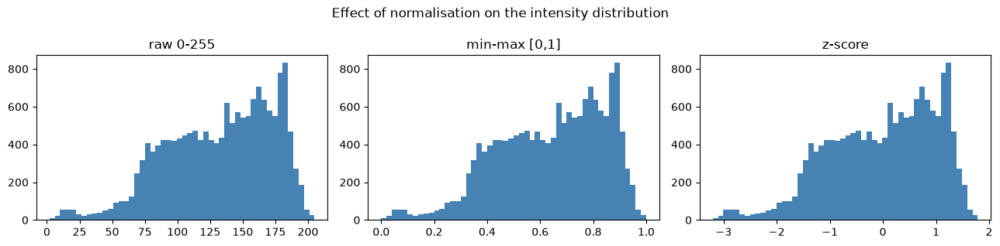

In [63]:
gray_01 = (gray_resized_np - gray_resized_np.min()) / (gray_resized_np.max() - gray_resized_np.min() + 1e-8)
mu, sigma = gray_01.mean(), gray_01.std()
gray_std = (gray_01 - mu) / sigma

for name, arr in [("raw", gray_resized_np), ("min-max [0,1]", gray_01), ("z-score", gray_std)]:
    print(f"{name:<15} min={arr.min():8.3f}  max={arr.max():8.3f}  mean={arr.mean():7.3f}  std={arr.std():7.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, arr, t in zip(ax, [gray_resized_np, gray_01, gray_std], ["raw 0-255", "min-max [0,1]", "z-score"]):
    a.hist(arr.ravel(), bins=50, color="steelblue"); a.set_title(t)
plt.suptitle("Effect of normalisation on the intensity distribution"); plt.tight_layout(); plt.show()

**Inference:** 
- Normalisation **changes the scale, not the shape** of the distribution — all three histograms look identical. 
- Min–max maps the pixels to [0, 1] (mean ≈ 0.64, a bright image); z-score centres them at 0 with unit variance (range ≈ −3.2 to 1.8, asymmetric because of the dark tail). 
- Scaled inputs keep activations and gradients in a stable range.

### A.1.3 Convert image into tensor format
PyTorch expects **(N, C, H, W)** = (batch, channels, height, width). A single grayscale image becomes **(1, 1, 128, 128)**.

In [64]:
# Manual conversion
gray_tensor = torch.from_numpy(gray_01).float().unsqueeze(0).unsqueeze(0)   # (1,1,H,W)

# Built-in pipeline
gray_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),                     # -> (1,H,W), float, scaled to [0,1]
])
gray_tensor_tv = gray_transform(gray_pil).unsqueeze(0)

print("Manual tensor     :", tuple(gray_tensor.shape), gray_tensor.dtype)
print("torchvision tensor:", tuple(gray_tensor_tv.shape), gray_tensor_tv.dtype)
print("Tensor value range:", gray_tensor.min().item(), "to", gray_tensor.max().item())

Manual tensor     : (1, 1, 128, 128) torch.float32
torchvision tensor: (1, 1, 128, 128) torch.float32
Tensor value range: 0.0 to 1.0


**Inference:** 
- Manual conversion and `torchvision.transforms` give the same **(1, 1, 128, 128)** float32 tensor with values in [0, 1] — batch = 1, channel = 1 (grayscale), 128×128 spatial size.

## A.2 — CNN operations: user-defined AND built-in

**Question (b):** *Apply CNN operations: Convolution layers, Activation function (ReLU), Pooling layers, Flattening operation, Dense layer for latent vector generation. Application of filters should be by both **User defined** as well as **in built** function.*

### A.2.1 User-defined (from-scratch) implementations

In [65]:
def conv2d_user(image, kernel, stride=1, padding=0, bias=0.0):
    # From-scratch 2-D convolution (cross-correlation), single or multi-channel.
    # image : (H, W) or (C, H, W);  kernel : (k, k) or (C, k, k)
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if image.ndim == 2:  image = image[None]
    if kernel.ndim == 2: kernel = kernel[None]
    C, H, W = image.shape
    _, kh, kw = kernel.shape
    if padding > 0:
        image = np.pad(image, ((0, 0), (padding, padding), (padding, padding)))
    out_h = (H - kh + 2 * padding) // stride + 1
    out_w = (W - kw + 2 * padding) // stride + 1
    out = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        for j in range(out_w):
            r, c = i * stride, j * stride
            region = image[:, r:r + kh, c:c + kw]
            out[i, j] = np.sum(region * kernel) + bias   # element-wise multiply and sum
    return out

def relu_user(x):
    return np.maximum(0, x)

def maxpool_user(x, size=2, stride=2):
    H, W = x.shape
    out_h, out_w = (H - size) // stride + 1, (W - size) // stride + 1
    out = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        for j in range(out_w):
            out[i, j] = x[i*stride:i*stride+size, j*stride:j*stride+size].max()
    return out

def flatten_user(x):
    return np.asarray(x).reshape(-1)

def dense_user(x, W, b):
    return W @ x + b

# Sanity check on a tiny example
X = np.arange(25).reshape(5, 5)
K = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
print("Input 5x5:\n", X)
print("Kernel:\n", K)
print("conv2d_user output (3x3):\n", conv2d_user(X, K))

Input 5x5:
 [[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]]
Kernel:
 [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]
conv2d_user output (3x3):
 [[-6. -6. -6.]
 [-6. -6. -6.]
 [-6. -6. -6.]]


**Inference:** 
- The 5×5 input increases by 1 per column, so its horizontal gradient is constant; the vertical-edge kernel therefore gives the **same value (−6) everywhere**. 
- The 3×3 output size matches the formula O = (5 − 3 + 0)/1 + 1 = 3, confirming the from-scratch convolution works.

### A.2.2 User-defined filters (hand-crafted kernels)
Each filter responds to a different pattern in the X-ray.

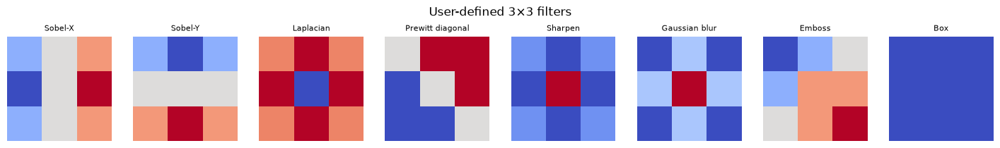

In [66]:
gray_filters = {
    "Sobel-X (vertical edges)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
    "Sobel-Y (horizontal edges)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32),
    "Laplacian (all edges)":      np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32),
    "Prewitt diagonal":           np.array([[0, 1, 1], [-1, 0, 1], [-1, -1, 0]], np.float32),
    "Sharpen":                    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
    "Gaussian blur":              np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], np.float32) / 16,
    "Emboss":                     np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float32),
    "Box (mean)":                 np.ones((3, 3), np.float32) / 9,
}
show_kernels(list(gray_filters.values()), [n.split(" (")[0] for n in gray_filters], "User-defined 3×3 filters")

**Inference:** 
- Edge kernels (Sobel, Laplacian, Prewitt) have positive and negative weights that **sum to 0** → they respond only to intensity *changes* and give 0 on flat regions. 
- Blur/box kernels have only positive weights summing to 1 → they average (smooth). 
- Sharpen and emboss sum to 1 → they keep brightness while boosting contrast/direction.

### A.2.3 Apply the filters with the **user-defined** convolution → ReLU → Max-pool

User-defined convolution of 8 filters took 0.429 s


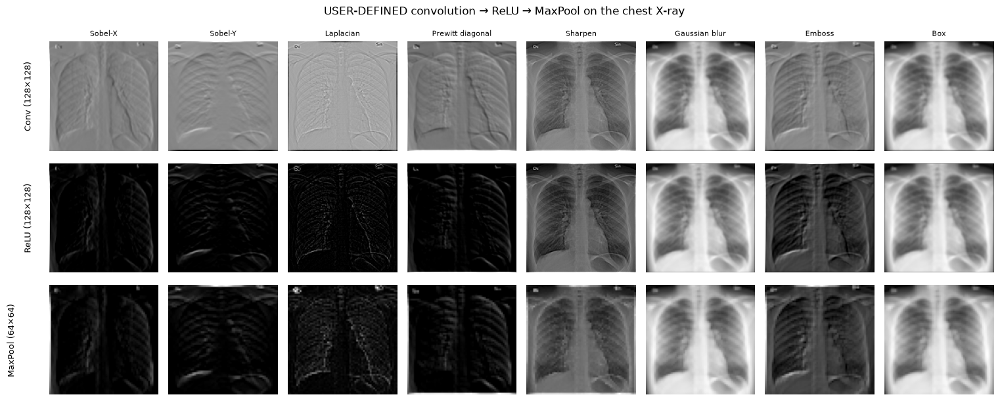

In [67]:
img = gray_01
t0 = time.perf_counter()
user_conv  = {n: conv2d_user(img, k, padding=1) for n, k in gray_filters.items()}
t_user = time.perf_counter() - t0
user_relu  = {n: relu_user(v) for n, v in user_conv.items()}
user_pool  = {n: maxpool_user(v) for n, v in user_relu.items()}
print(f"User-defined convolution of 8 filters took {t_user:.3f} s")

names = list(gray_filters)
fig, axes = plt.subplots(3, len(names), figsize=(len(names) * 1.9, 6.3))
for j, n in enumerate(names):
    axes[0, j].imshow(user_conv[n], cmap="gray"); axes[0, j].set_title(n.split(" (")[0], fontsize=8)
    axes[1, j].imshow(user_relu[n], cmap="gray")
    axes[2, j].imshow(user_pool[n], cmap="gray")
for a in axes.ravel(): a.axis("off")
for r, lbl in enumerate(["Conv (128×128)", "ReLU (128×128)", "MaxPool (64×64)"]):
    axes[r, 0].text(-20, IMG_SIZE // (2 if r == 2 else 1) // 2, lbl, rotation=90, va="center", ha="right", fontsize=9)
plt.suptitle("USER-DEFINED convolution → ReLU → MaxPool on the chest X-ray"); plt.tight_layout(); plt.show()

**Inference:** 
- **Sobel-X** outlines vertical structures: rib cage sides, heart border, spine. **Sobel-Y** picks up horizontal structures: ribs, clavicles, diaphragm.
- **Laplacian** gives thin outlines of all edges but also amplifies noise.
- **Blur / box** give a smoothed X-ray; **sharpen / emboss** enhance rib contours.
- After **ReLU**, edge maps become mostly black — only one edge polarity (positive responses) survives.
- **MaxPool** halves the size (128 → 64) but the strongest edges are preserved.

### A.2.4 Apply the **same** filters with the **built-in** function (`torch.nn.functional.conv2d`, `F.relu`, `F.max_pool2d`)
The kernels are stacked into a weight tensor of shape **(out_channels=8, in_channels=1, 3, 3)** and applied in one call.

Built-in conv output : (1, 8, 128, 128) | time 2.15 ms
Built-in pool output : (1, 8, 64, 64)
Sobel-X (vertical edges)     max|user - builtin|: conv=4.77e-07  pool=3.58e-07
Sobel-Y (horizontal edges)   max|user - builtin|: conv=4.77e-07  pool=3.58e-07
Laplacian (all edges)        max|user - builtin|: conv=3.58e-07  pool=3.58e-07
Prewitt diagonal             max|user - builtin|: conv=2.38e-07  pool=2.38e-07
Sharpen                      max|user - builtin|: conv=5.36e-07  pool=5.36e-07
Gaussian blur                max|user - builtin|: conv=1.79e-07  pool=1.19e-07
Emboss                       max|user - builtin|: conv=5.96e-07  pool=5.36e-07
Box (mean)                   max|user - builtin|: conv=1.79e-07  pool=1.79e-07

Speed-up of built-in over user-defined: ~200×


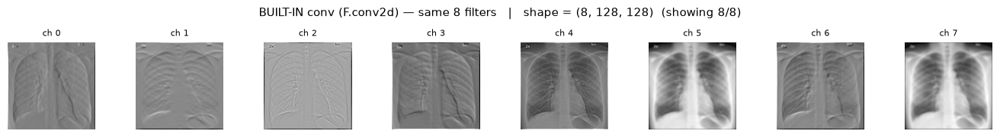

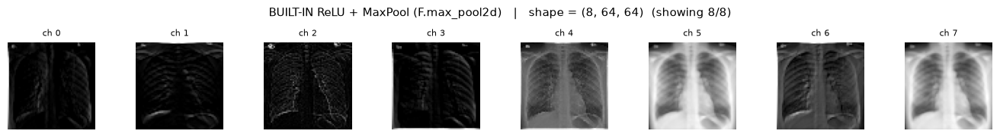

In [68]:
weight = torch.tensor(np.stack(list(gray_filters.values())))[:, None]   # (8,1,3,3)
t0 = time.perf_counter()
builtin_conv = F.conv2d(gray_tensor, weight, padding=1)                  # (1,8,128,128)
t_builtin = time.perf_counter() - t0
builtin_relu = F.relu(builtin_conv)
builtin_pool = F.max_pool2d(builtin_relu, 2)

print("Built-in conv output :", tuple(builtin_conv.shape), f"| time {t_builtin*1000:.2f} ms")
print("Built-in pool output :", tuple(builtin_pool.shape))

# Verify that the user-defined and built-in results are identical
for i, n in enumerate(names):
    d_conv = np.abs(user_conv[n] - builtin_conv[0, i].numpy()).max()
    d_pool = np.abs(user_pool[n] - builtin_pool[0, i].numpy()).max()
    print(f"{n:<28} max|user - builtin|: conv={d_conv:.2e}  pool={d_pool:.2e}")
print(f"\nSpeed-up of built-in over user-defined: ~{t_user / max(t_builtin, 1e-9):,.0f}×")

show_feature_maps(builtin_conv, "BUILT-IN conv (F.conv2d) — same 8 filters", cmap="gray")
show_feature_maps(builtin_pool, "BUILT-IN ReLU + MaxPool (F.max_pool2d)", cmap="gray")

**Observation:** The user-defined and built-in outputs match to floating-point precision (≈1e-7 difference), confirming the from-scratch implementation. The built-in version is orders of magnitude faster because it is vectorised (im2col / optimised BLAS) instead of Python loops.

- Sobel-X highlights the **rib borders and lateral lung edges**; Sobel-Y the **diaphragm and clavicles**.
- Laplacian responds to all edges and fine texture; blur/box filters suppress noise; sharpen/emboss enhance the anatomy's contours.
- ReLU removes negative responses (only one edge polarity survives); max-pool halves the resolution while keeping the strongest response.
- The built-in feature maps are visually identical to the user-defined ones above.

### A.2.5 User-defined Flatten and Dense layer (latent vector from the filter bank)

Pooled stack: (8, 64, 64) → flattened: (32768,) → latent: (64,)
max|user - builtin| latent: 7.748604e-07


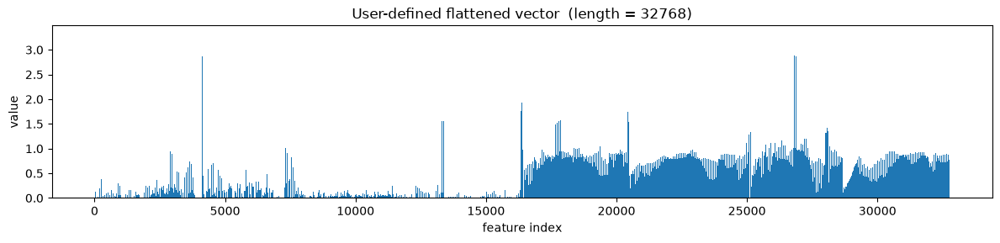

min=0.0000  max=3.3251  mean=0.4124  non-zero=27879/32768


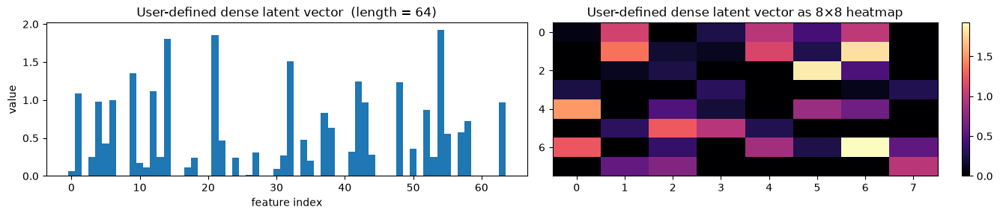

min=0.0000  max=1.9225  mean=0.4089  non-zero=39/64


In [69]:
stack = np.stack([user_pool[n] for n in names])             # (8, 64, 64)
flat  = flatten_user(stack)                                  # 8*64*64 = 32768
rng   = np.random.default_rng(0)
LATENT_DIM = 64
W_d = rng.normal(0, np.sqrt(2 / flat.size), (LATENT_DIM, flat.size)).astype(np.float32)  # He init
b_d = np.zeros(LATENT_DIM, np.float32)
latent_user = relu_user(dense_user(flat, W_d, b_d))

# Built-in equivalent
dense = nn.Linear(flat.size, LATENT_DIM)
with torch.no_grad():
    dense.weight.copy_(torch.from_numpy(W_d)); dense.bias.zero_()
latent_builtin = F.relu(dense(torch.flatten(builtin_pool, 1)))

print("Pooled stack:", stack.shape, "→ flattened:", flat.shape, "→ latent:", latent_user.shape)
print("max|user - builtin| latent:", np.abs(latent_user - latent_builtin[0].detach().numpy()).max())
show_vector(flat, "User-defined flattened vector")
show_vector(latent_user, "User-defined dense latent vector", heat_cols=8)

**Inference:** 
- The 8 pooled maps (8×64×64) flatten to a **32,768-long** vector; the dense layer compresses it to **64 values** (a 512× reduction). 
- The flattened vector is mostly non-zero (blur/box channels are positive everywhere), whereas the latent vector after ReLU is **sparse** (about 40% of its entries are zero). 
- The user-defined and built-in dense layers give the same latent vector.

## A.3 — CNN architecture for the grayscale medical image

- **Question:** *Design a CNN architecture to extract meaningful latent representations from the image.*
- **Question:** *Write the architecture used for extracting features for the grayscale image.*

### Architecture: `GrayMedCNN`

| # | Layer | Configuration | Output shape | Parameters |
|---|---|---|---|---|
| 0 | Input | grayscale X-ray | 1 × 128 × 128 | – |
| 1 | Conv1 | 8 filters, 3×3, stride 1, pad 1 | 8 × 128 × 128 | 8·(1·9)+8 = **80** |
| 2 | ReLU1 | – | 8 × 128 × 128 | 0 |
| 3 | MaxPool1 | 2×2, stride 2 | 8 × 64 × 64 | 0 |
| 4 | Conv2 | 16 filters, 3×3, stride 1, pad 1 | 16 × 64 × 64 | 16·(8·9)+16 = **1,168** |
| 5 | ReLU2 | – | 16 × 64 × 64 | 0 |
| 6 | MaxPool2 | 2×2, stride 2 | 16 × 32 × 32 | 0 |
| 7 | Conv3 | 32 filters, 3×3, stride 1, pad 1 | 32 × 32 × 32 | 32·(16·9)+32 = **4,640** |
| 8 | ReLU3 | – | 32 × 32 × 32 | 0 |
| 9 | MaxPool3 | 2×2, stride 2 | 32 × 16 × 16 | 0 |
| 10 | Flatten | – | 8,192 | 0 |
| 11 | Dense (latent) | 8192 → 128, ReLU | **128 (latent vector)** | **1,048,704** |
| 12 | Classifier | 128 → 2 (Normal / Abnormal) | 2 | 258 |

Design choices:
- **Filters double (8 → 16 → 32) while spatial size halves** — the network trades spatial detail for richer, more abstract channels.
- **Conv1 is initialised with the 8 user-defined filters** from A.2.2, so its feature maps are directly interpretable. Conv2/Conv3 use He (Kaiming) initialisation.
- The **128-D dense output is the latent representation**; the classifier head is kept so the same network can be trained for Normal vs Abnormal classification.

In [70]:
class GrayMedCNN(nn.Module):
    def __init__(self, f1=8, f2=16, f3=32, latent_dim=128, n_classes=2, img_size=128):
        super().__init__()
        self.conv1 = nn.Conv2d(1,  f1, 3, stride=1, padding=1); self.relu1 = nn.ReLU(); self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(f1, f2, 3, stride=1, padding=1); self.relu2 = nn.ReLU(); self.pool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(f2, f3, 3, stride=1, padding=1); self.relu3 = nn.ReLU(); self.pool3 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        flat_dim = f3 * (img_size // 8) ** 2
        self.fc_latent = nn.Linear(flat_dim, latent_dim); self.relu_latent = nn.ReLU()
        self.classifier = nn.Linear(latent_dim, n_classes)

    def extract_features(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        return self.relu_latent(self.fc_latent(self.flatten(x)))   # latent vector

    def forward(self, x):
        return self.classifier(self.extract_features(x))

gray_model = GrayMedCNN()

# Load the user-defined filters into the built-in Conv1 layer
with torch.no_grad():
    gray_model.conv1.weight.copy_(weight)        # (8,1,3,3)
    gray_model.conv1.bias.zero_()
gray_model.eval()

print(gray_model, "\n")
model_summary(gray_model, (1, IMG_SIZE, IMG_SIZE))

GrayMedCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc_latent): Linear(in_features=8192, out_features=128, bias=True)
  (relu_latent): ReLU()
  (classifier): Linear(in_features=128, out_features=2, bias=True)
) 

Layer         Type        Output shape              Params
----------------------------------------------------------
conv1         Conv2d      (1, 8, 128, 128)              80
relu1         ReLU        (1, 8, 128, 128)               0
po

**Inference:** The printed shapes and parameter counts match the architecture table. The conv layers have only **5,888** parameters, while the dense latent layer has **1,048,704** (≈ 99% of the model) — convolution is parameter-efficient because the same small kernel is shared across the whole image.

## A.4 — Extract and visualise feature maps of every CNN layer

**Question (c):** *Extract and visualize:*
- *Intermediate feature maps after each convolution layer.*
- *Feature maps after pooling layers.*
- *Feature maps generated by each CNN layer.*
- *Final latent feature vector representation.*

Forward **hooks** capture the output of every layer during a single forward pass.

In [71]:
handles = register_hooks(gray_model)
with torch.no_grad():
    logits = gray_model(gray_tensor)
for h in handles: h.remove()
gact = gray_model.activations
for k, v in gact.items():
    print(f"{k:<12} -> {tuple(v.shape)}")

conv1        -> (1, 8, 128, 128)
relu1        -> (1, 8, 128, 128)
pool1        -> (1, 8, 64, 64)
conv2        -> (1, 16, 64, 64)
relu2        -> (1, 16, 64, 64)
pool2        -> (1, 16, 32, 32)
conv3        -> (1, 32, 32, 32)
relu3        -> (1, 32, 32, 32)
pool3        -> (1, 32, 16, 16)
flatten      -> (1, 8192)
fc_latent    -> (1, 128)
relu_latent  -> (1, 128)
classifier   -> (1, 2)


### Block 1 — Conv1 → ReLU1 → MaxPool1  (low-level: edges & intensity transitions)

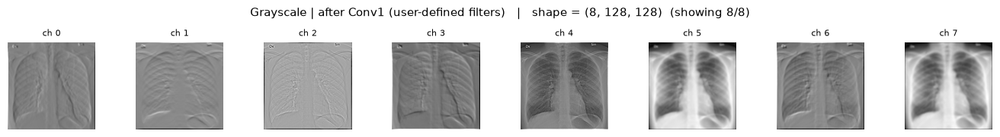

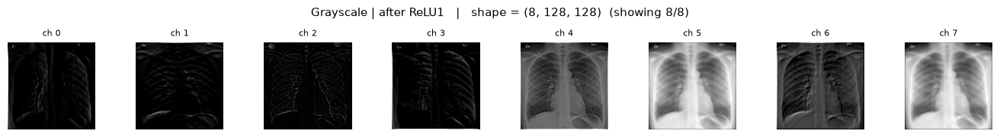

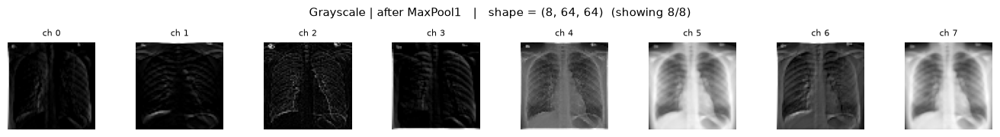

In [72]:
show_feature_maps(gact["conv1"], "Grayscale | after Conv1 (user-defined filters)", cmap="gray")
show_feature_maps(gact["relu1"], "Grayscale | after ReLU1", cmap="gray")
show_feature_maps(gact["pool1"], "Grayscale | after MaxPool1", cmap="gray")

**Inference:** 
- Conv1 maps are sharp and anatomically meaningful because they use the hand-crafted filters: edge channels show ribs and the heart border, smoothing channels show the overall X-ray. 
- ReLU blacks out negative edges; MaxPool1 halves the resolution with little visible loss.

### Block 2 — Conv2 → ReLU2 → MaxPool2  (mid-level: combinations of edges → local texture)

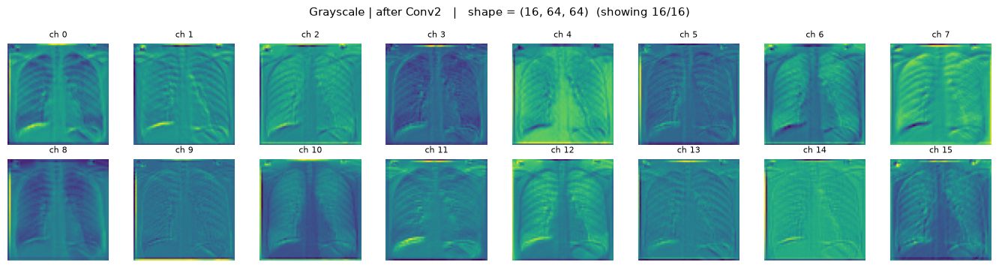

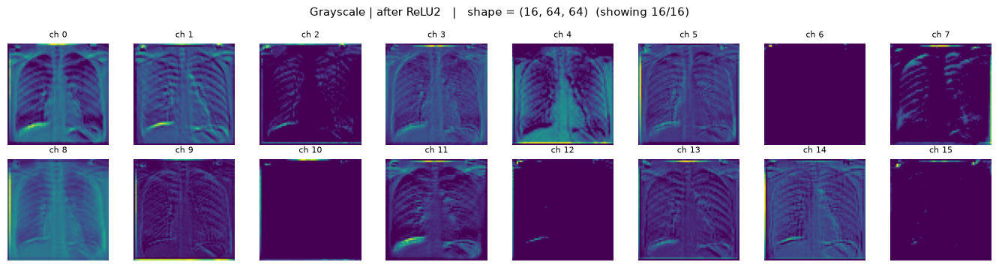

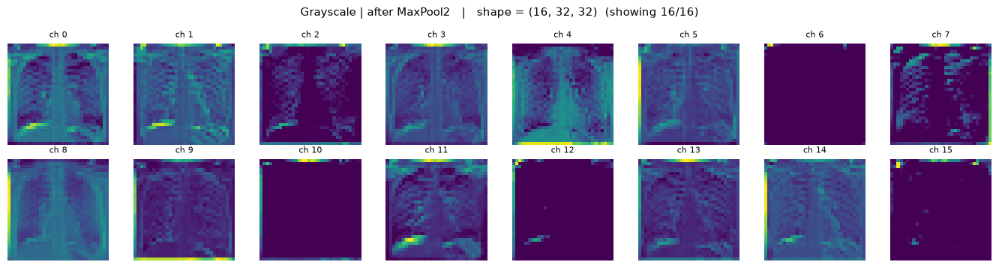

In [73]:
show_feature_maps(gact["conv2"], "Grayscale | after Conv2", max_maps=16)
show_feature_maps(gact["relu2"], "Grayscale | after ReLU2", max_maps=16)
show_feature_maps(gact["pool2"], "Grayscale | after MaxPool2", max_maps=16)

**Inference:** 
- Conv2 channels are **mixtures** of the 8 Conv1 maps: the lung fields, rib pattern and mediastinum are still visible but less sharp. 
- After ReLU some channels become almost completely dark (their filters respond negatively everywhere) — these random, untrained filters are not yet useful, which training would fix.

### Block 3 — Conv3 → ReLU3 → MaxPool3  (higher-level: coarse regions / structures)

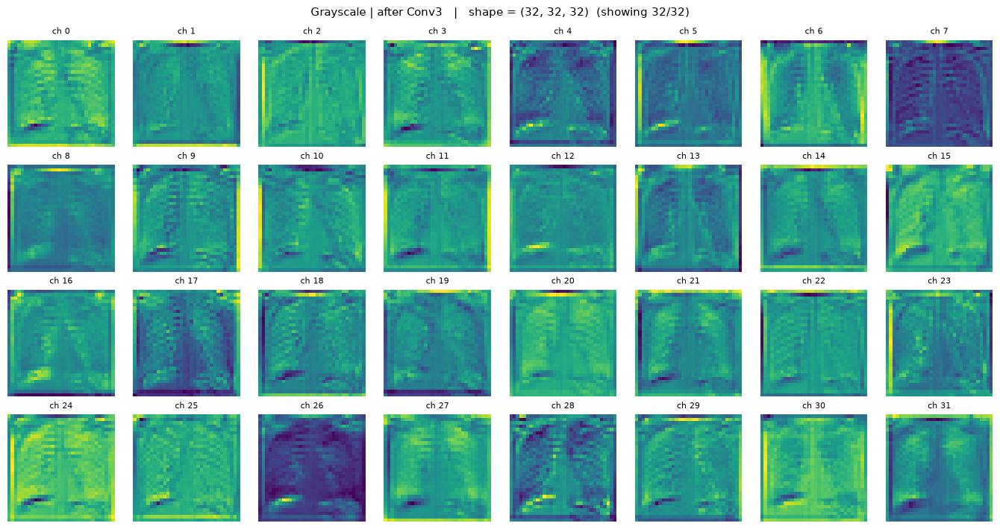

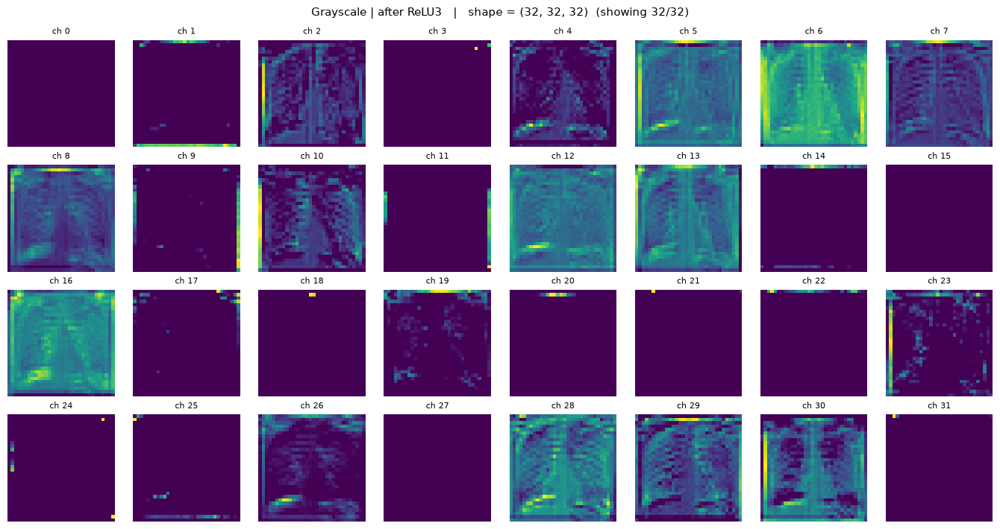

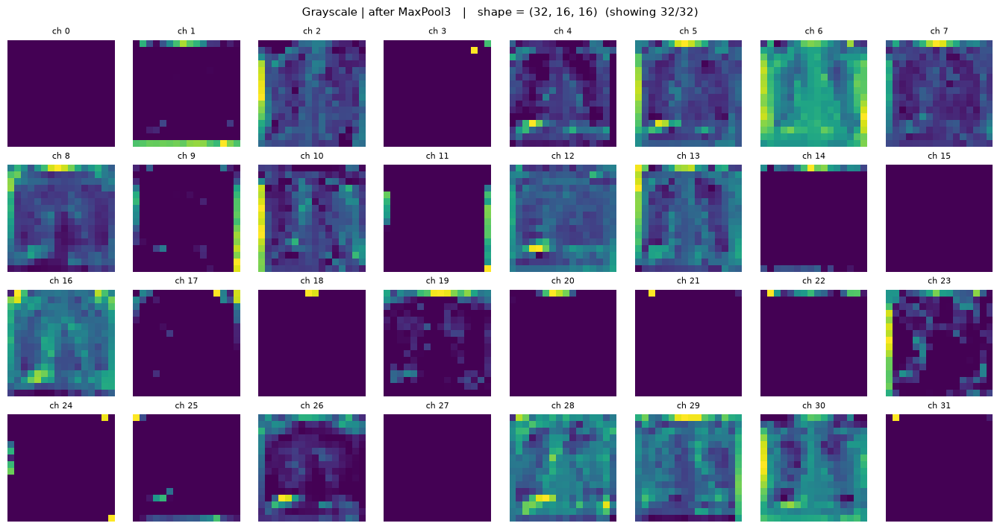

In [74]:
show_feature_maps(gact["conv3"], "Grayscale | after Conv3", max_maps=32)
show_feature_maps(gact["relu3"], "Grayscale | after ReLU3", max_maps=32)
show_feature_maps(gact["pool3"], "Grayscale | after MaxPool3", max_maps=32)

**Inference:** 
- At 32×32 and then 16×16, individual ribs are no longer visible; the maps show **coarse regions** — lung areas vs. the central heart/spine and the diaphragm. 
- More channels are inactive after ReLU, so the representation becomes more abstract and sparse as depth increases.

### Flattened vector and final latent feature vector

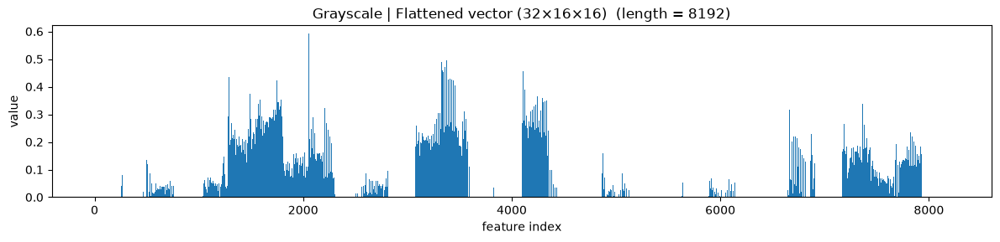

min=0.0000  max=0.5922  mean=0.0713  non-zero=3933/8192


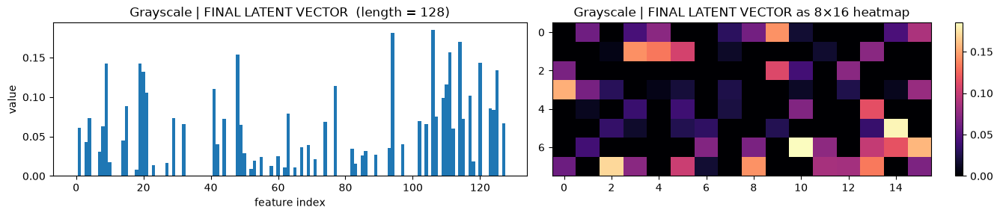

min=0.0000  max=0.1850  mean=0.0325  non-zero=61/128
Classifier logits (untrained): [[-0.0972  0.0119]]


In [75]:
show_vector(gact["flatten"], "Grayscale | Flattened vector (32×16×16)")
show_vector(gact["relu_latent"], "Grayscale | FINAL LATENT VECTOR", heat_cols=16)
print("Classifier logits (untrained):", logits.numpy().round(4))

**Inference:** 
- The flattened vector (32×16×16 = **8,192** values) is about half zeros, as expected after ReLU. 
- The dense layer compresses it to the **128-D latent vector**, where roughly half of the entries are active — this compact vector summarises the whole X-ray. 
- The two classifier logits are near 0 because the network is untrained.

### Summary figure — the whole grayscale pipeline in one view

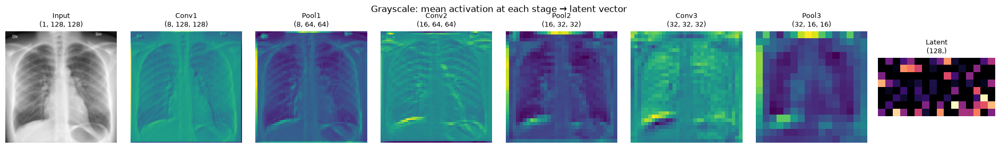

In [76]:
stages = [("Input", gray_tensor), ("Conv1", gact["conv1"]), ("Pool1", gact["pool1"]),
          ("Conv2", gact["conv2"]), ("Pool2", gact["pool2"]), ("Conv3", gact["conv3"]), ("Pool3", gact["pool3"])]
fig, axes = plt.subplots(1, len(stages) + 1, figsize=(19, 2.8))
for ax, (n, t) in zip(axes, stages):
    m = t[0].mean(0) if n != "Input" else t[0, 0]
    ax.imshow(m, cmap="gray" if n == "Input" else "viridis")
    ax.set_title(f"{n}\n{tuple(t.shape[1:])}", fontsize=9); ax.axis("off")
lat = gact["relu_latent"][0].numpy()
axes[-1].imshow(lat.reshape(8, 16), cmap="magma"); axes[-1].set_title("Latent\n(128,)", fontsize=9); axes[-1].axis("off")
plt.suptitle("Grayscale: mean activation at each stage → latent vector"); plt.tight_layout(); plt.show()

**Inference (grayscale pipeline):**
- **Conv1** maps are sharp and interpretable (ribs, heart border, diaphragm) because they use the hand-crafted filters.
- **Conv2/Conv3** mix the Conv1 channels; their maps become blurrier and more region-like — they encode *where* groups of edges occur (lung fields vs. mediastinum).
- Each **pooling** step halves resolution (128 → 64 → 32 → 16), increasing the receptive field and giving tolerance to small shifts.
- The **128-D latent vector** is a compact descriptor (8,192 → 128, a 64× reduction) of the whole X-ray. After training (e.g. on the Kaggle chest-X-ray pneumonia dataset) it would become discriminative for Normal vs Pneumonia.

# PART B — RGB Image

- **Question:** *Select any RGB image of your choice (animal, object, natural scene, etc.).*
- **Question:** *Implement a CNN model to extract latent features.*


### B.0 — Visualise the input RGB image

**Question:** *Visualize: Input RGB image.*

Original size (W×H): (1500, 1800) | shape: (1800, 1500, 3) | dtype: uint8


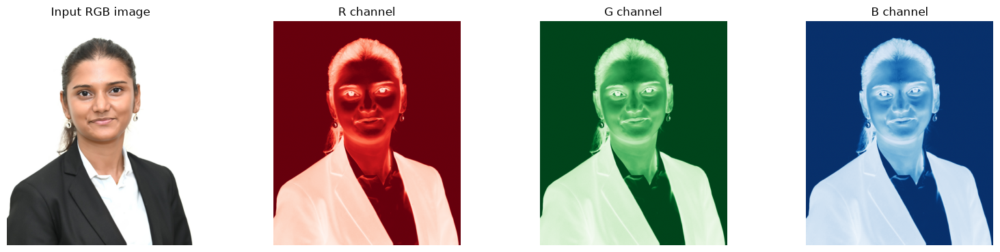

In [77]:
rgb_pil = Image.open(RGB_PATH).convert("RGB")
rgb_np  = np.array(rgb_pil)
print("Original size (W×H):", rgb_pil.size, "| shape:", rgb_np.shape, "| dtype:", rgb_np.dtype)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
ax[0].imshow(rgb_np); ax[0].set_title("Input RGB image")
for i, (c, cm) in enumerate(zip("RGB", ["Reds", "Greens", "Blues"])):
    ax[i + 1].imshow(rgb_np[..., i], cmap=cm); ax[i + 1].set_title(f"{c} channel")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Inference:** 
- The white background is bright in **all three channels** (R = G = B ≈ 255). 
- Skin is brightest in the **R** channel and darker in **B**, which is typical of skin tones; the black blazer is dark in every channel. 
- So colour carries extra information (skin vs. background vs. clothing) that a grayscale image would lose.

## B.1 — RGB image pre-processing

**Question:** *Perform: RGB image preprocessing.*

Resized (HWC): (128, 128, 3) | tensor (NCHW): (1, 3, 128, 128)
R: after [0,1] mean=0.731 | after normalise mean=1.075 std=1.515
G: after [0,1] mean=0.700 | after normalise mean=1.090 std=1.548
B: after [0,1] mean=0.682 | after normalise mean=1.229 std=1.575
torchvision tensor: (1, 3, 128, 128)


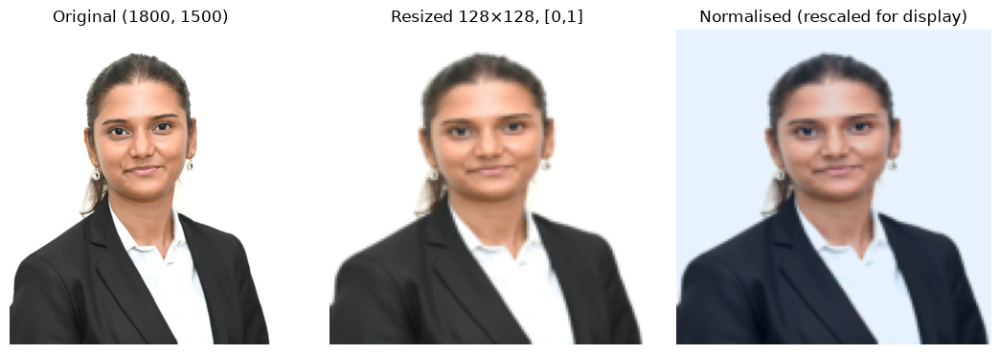

In [78]:
RGB_SIZE = 128
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD  = np.array([0.229, 0.224, 0.225], np.float32)

# Manual pipeline
rgb_resized = np.array(rgb_pil.resize((RGB_SIZE, RGB_SIZE), Image.BILINEAR)).astype(np.float32)  # (H,W,3)
rgb_01   = rgb_resized / 255.0
rgb_norm = (rgb_01 - MEAN) / STD
rgb_tensor = torch.from_numpy(rgb_norm.transpose(2, 0, 1)).float().unsqueeze(0)                   # (1,3,H,W)

# Built-in pipeline
rgb_transform = T.Compose([T.Resize((RGB_SIZE, RGB_SIZE)), T.ToTensor(), T.Normalize(MEAN.tolist(), STD.tolist())])
rgb_tensor_tv = rgb_transform(rgb_pil).unsqueeze(0)

print("Resized (HWC):", rgb_resized.shape, "| tensor (NCHW):", tuple(rgb_tensor.shape))
for c, ch in enumerate("RGB"):
    print(f"{ch}: after [0,1] mean={rgb_01[..., c].mean():.3f} | after normalise mean={rgb_norm[..., c].mean():.3f} std={rgb_norm[..., c].std():.3f}")
print("torchvision tensor:", tuple(rgb_tensor_tv.shape))

def denorm(t):
    x = t[0].numpy().transpose(1, 2, 0) * STD + MEAN
    return np.clip(x, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(rgb_np); ax[0].set_title(f"Original {rgb_np.shape[:2]}")
ax[1].imshow(rgb_01); ax[1].set_title(f"Resized {RGB_SIZE}×{RGB_SIZE}, [0,1]")
ax[2].imshow(np.clip((rgb_norm - rgb_norm.min()) / (rgb_norm.max() - rgb_norm.min()), 0, 1))
ax[2].set_title("Normalised (rescaled for display)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Inference:** 
- The 1800×1500 portrait is resized to 128×128; the face, hair and blazer remain recognisable. 
- The R channel has the highest mean (warm skin tones) and B the lowest. 
- After ImageNet normalisation each channel is centred near 0, and the tensor has the shape **(1, 3, 128, 128)**. 
- The normalised image looks slightly washed-out only because it is rescaled for display.

## B.2 — Apply convolution filters to extract edge, texture and shape features

**Question:** *Apply convolution filters to extract: Edge features, Texture features, Shape features, High-level semantic features.*

For an RGB image each filter has shape **(3, k, k)** — one k×k slice per colour channel — and the three responses are **summed** into one output map. Filter families:

| Feature level | Filters used | What they detect |
|---|---|---|
| **Edge** | Sobel-X, Sobel-Y, Laplacian, Scharr | intensity discontinuities (outlines, fur boundaries, eyes) |
| **Texture** | Gabor filters at 0°, 45°, 90°, 135° | oriented periodic patterns (fur stripes, whiskers) |
| **Shape** | Laplacian-of-Gaussian (7×7), Difference-of-Gaussians (7×7), large box | blobs & coarse object regions (eyes, head, body) |
| **High-level semantic** | Deep CNN layers (B.3, B.4) | object parts and object identity — **cannot be hand-designed**, must be learned |

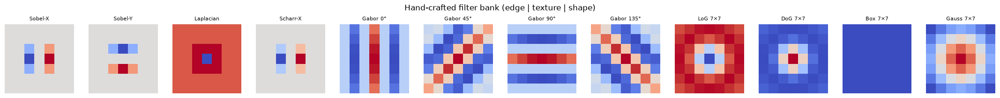

RGB filter-bank weight tensor shape: (12, 3, 7, 7) (out_ch, in_ch, k, k)


In [79]:
def gabor_kernel(ksize=7, sigma=2.0, theta=0.0, lambd=4.0, gamma=0.5, psi=0.0):
    half = ksize // 2
    y, x = np.mgrid[-half:half + 1, -half:half + 1].astype(np.float32)
    xr =  x * np.cos(theta) + y * np.sin(theta)
    yr = -x * np.sin(theta) + y * np.cos(theta)
    g = np.exp(-(xr**2 + gamma**2 * yr**2) / (2 * sigma**2)) * np.cos(2 * np.pi * xr / lambd + psi)
    return (g - g.mean()).astype(np.float32)

def gaussian_kernel(ksize, sigma):
    half = ksize // 2
    y, x = np.mgrid[-half:half + 1, -half:half + 1]
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2)); return (g / g.sum()).astype(np.float32)

def log_kernel(ksize=7, sigma=1.4):
    half = ksize // 2
    y, x = np.mgrid[-half:half + 1, -half:half + 1].astype(np.float32)
    r2 = x**2 + y**2
    k = -(1 - r2 / (2 * sigma**2)) * np.exp(-r2 / (2 * sigma**2))
    return (k - k.mean()).astype(np.float32)

def pad_to(k, size=7):
    p = (size - k.shape[0]) // 2
    return np.pad(k, p)

rgb_filter_bank = {
    # ---- edge ----
    "Edge: Sobel-X":    np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
    "Edge: Sobel-Y":    np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32),
    "Edge: Laplacian":  np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], np.float32),
    "Edge: Scharr-X":   np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], np.float32) / 4,
    # ---- texture ----
    "Texture: Gabor 0°":   gabor_kernel(theta=0),
    "Texture: Gabor 45°":  gabor_kernel(theta=np.pi / 4),
    "Texture: Gabor 90°":  gabor_kernel(theta=np.pi / 2),
    "Texture: Gabor 135°": gabor_kernel(theta=3 * np.pi / 4),
    # ---- shape ----
    "Shape: LoG 7×7":      log_kernel(7, 1.4),
    "Shape: DoG 7×7":      gaussian_kernel(7, 1.0) - gaussian_kernel(7, 2.5),
    "Shape: Box 7×7":      np.ones((7, 7), np.float32) / 49,
    "Shape: Gauss 7×7":    gaussian_kernel(7, 2.0),
}
bank_names = list(rgb_filter_bank)
show_kernels([pad_to(k) if k.shape[0] < 7 else k for k in rgb_filter_bank.values()],
             [n.split(": ")[1] for n in bank_names], "Hand-crafted filter bank (edge | texture | shape)")

# Make every kernel a (3,7,7) RGB kernel: the same 2-D kernel on each channel, divided by 3
rgb_kernels = np.stack([np.repeat(pad_to(k)[None] if k.shape[0] < 7 else k[None], 3, 0) / 3
                        for k in rgb_filter_bank.values()]).astype(np.float32)        # (12,3,7,7)
print("RGB filter-bank weight tensor shape:", rgb_kernels.shape, "(out_ch, in_ch, k, k)")

**Inference:** 
- The **edge** kernels are small (3×3) derivative filters; the **Gabor** kernels are striped patterns at 4 orientations that match oriented textures; the **shape** kernels are large (7×7) and smooth — LoG/DoG are "blob detectors" (centre vs. surround), while box/Gaussian capture coarse regions. 
- Each 2-D kernel is copied across R, G, B, giving a (12, 3, 7, 7) weight tensor.

### B.2.1 Filter bank applied with the **user-defined** multi-channel convolution

In [80]:
rgb_chw = rgb_norm.transpose(2, 0, 1)                  # (3,128,128)
t0 = time.perf_counter()
rgb_user_maps = np.stack([conv2d_user(rgb_chw, k, padding=3) for k in rgb_kernels])   # (12,128,128)
t_user_rgb = time.perf_counter() - t0
print(f"User-defined RGB convolution (12 filters × 3 channels): {t_user_rgb:.2f} s -> {rgb_user_maps.shape}")

User-defined RGB convolution (12 filters × 3 channels): 0.68 s -> (12, 128, 128)


### B.2.2 Same filter bank with the **built-in** `F.conv2d`, and visualisation by feature type

Built-in: 2.14 ms | max|user - builtin| = 7.63e-06


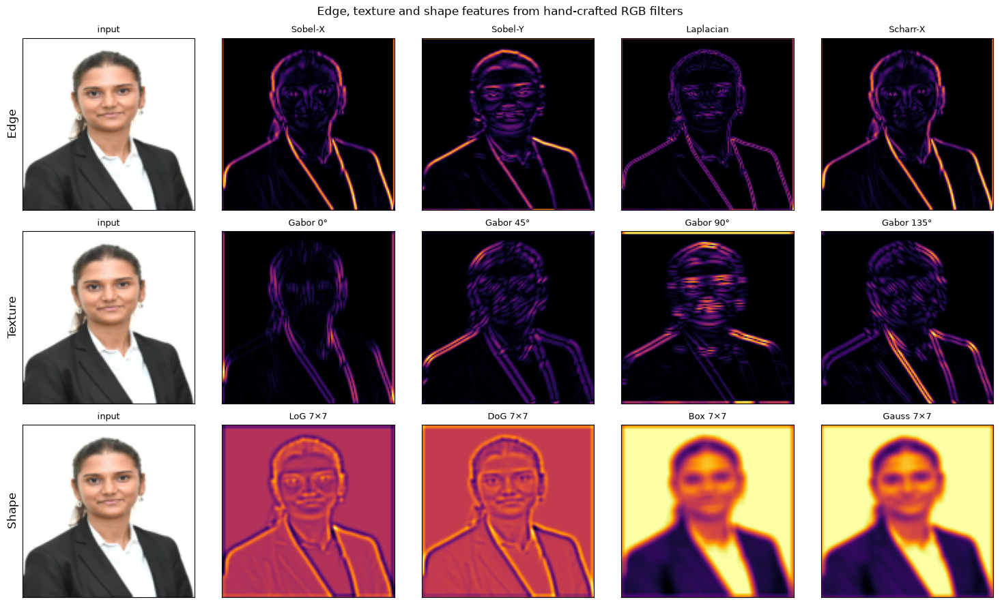

In [81]:
t0 = time.perf_counter()
rgb_builtin_maps = F.conv2d(rgb_tensor, torch.from_numpy(rgb_kernels), padding=3)       # (1,12,128,128)
t_builtin_rgb = time.perf_counter() - t0
print(f"Built-in: {t_builtin_rgb*1000:.2f} ms | max|user - builtin| = "
      f"{np.abs(rgb_user_maps - rgb_builtin_maps[0].numpy()).max():.2e}")

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for r, group in enumerate(["Edge", "Texture", "Shape"]):
    idx = [i for i, n in enumerate(bank_names) if n.startswith(group)]
    axes[r, 0].imshow(rgb_01); axes[r, 0].set_title("input", fontsize=9)
    axes[r, 0].set_ylabel(group, fontsize=12)
    for c, i in enumerate(idx):
        m = rgb_builtin_maps[0, i].numpy()
        if group != "Shape": m = np.abs(m)       # magnitude of response for edges/texture
        axes[r, c + 1].imshow(m, cmap="inferno"); axes[r, c + 1].set_title(bank_names[i].split(": ")[1], fontsize=9)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle("Edge, texture and shape features from hand-crafted RGB filters"); plt.tight_layout(); plt.show()

**Inference:**
- **Edge filters** light up at object boundaries: the face outline, hair, eyes, lips and the blazer's lapels and shoulders. Sobel-X favours vertical lapel edges, Sobel-Y the horizontal eyebrows, eyes and mouth; the Laplacian gives thin outlines of everything.
- **Gabor texture filters** respond to oriented patterns: 45° and 135° highlight the diagonal lapels, 90° responds to horizontal facial features (eyes, eyebrows, mouth), and 0° gives the weakest response (few vertical textures).
- **Shape filters**: LoG/DoG outline the whole figure and the eye/mouth blobs, while box/Gaussian blur the image into a coarse **silhouette** (dark blazer vs. white background).
- The thin bright lines along the image border are a **zero-padding artefact** (a white background next to zero padding looks like an edge).
- None of these hand-crafted filters "knows" this is a person → **semantic features must be learned** by deeper, trained layers.
- User-defined and built-in results match (difference ≈ 1e-6).

## B.3 — CNN architecture for the RGB image

**Question:** *Implement a CNN model to extract latent features.*
**Question:** *Write the architecture used for extracting features for the RGB image.*

### Architecture: `RGBFeatureCNN` (4 blocks — each block targets one feature level)

| # | Block / layer | Configuration | Output shape | Parameters | Feature level |
|---|---|---|---|---|---|
| 0 | Input | normalised RGB | 3 × 128 × 128 | – | – |
| 1 | Conv1 + ReLU | 16 filters, 3×3, pad 1 | 16 × 128 × 128 | 16·(3·9)+16 = **448** | **Edges / colour** |
| 2 | MaxPool1 | 2×2 | 16 × 64 × 64 | 0 | |
| 3 | Conv2 + ReLU | 32 filters, 3×3, pad 1 | 32 × 64 × 64 | 32·(16·9)+32 = **4,640** | **Textures** |
| 4 | MaxPool2 | 2×2 | 32 × 32 × 32 | 0 | |
| 5 | Conv3 + ReLU | 64 filters, 3×3, pad 1 | 64 × 32 × 32 | 64·(32·9)+64 = **18,496** | **Shapes / parts** |
| 6 | MaxPool3 | 2×2 | 64 × 16 × 16 | 0 | |
| 7 | Conv4 + ReLU | 128 filters, 3×3, pad 1 | 128 × 16 × 16 | 128·(64·9)+128 = **73,856** | **High-level semantic** |
| 8 | MaxPool4 | 2×2 | 128 × 8 × 8 | 0 | |
| 9 | Flatten | – | 8,192 | 0 | |
| 10 | Dense (latent) + ReLU | 8192 → 256 | **256 (latent vector)** | **2,097,408** | global descriptor |
| 11 | Classifier | 256 → 10 | 10 | 2,570 | class scores |

- **Conv1** is partly initialised with interpretable kernels: Sobel-X/Y, Laplacian, diagonal edge (on luminance) and 4 colour-opponent filters (R−G, G−R, B−Y, Y−B); the remaining 8 are random. Deeper layers use Kaiming initialisation.
- The latent vector is taken from the dense layer **before the classification layer**.

In [82]:
class RGBFeatureCNN(nn.Module):
    def __init__(self, filters=(16, 32, 64, 128), latent_dim=256, n_classes=10, img_size=128):
        super().__init__()
        f1, f2, f3, f4 = filters
        self.conv1 = nn.Conv2d(3,  f1, 3, padding=1); self.relu1 = nn.ReLU(); self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(f1, f2, 3, padding=1); self.relu2 = nn.ReLU(); self.pool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Conv2d(f2, f3, 3, padding=1); self.relu3 = nn.ReLU(); self.pool3 = nn.MaxPool2d(2)
        self.conv4 = nn.Conv2d(f3, f4, 3, padding=1); self.relu4 = nn.ReLU(); self.pool4 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc_latent = nn.Linear(f4 * (img_size // 16) ** 2, latent_dim); self.relu_latent = nn.ReLU()
        self.classifier = nn.Linear(latent_dim, n_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def extract_features(self, x):
        for i in range(1, 5):
            x = getattr(self, f"pool{i}")(getattr(self, f"relu{i}")(getattr(self, f"conv{i}")(x)))
        return self.relu_latent(self.fc_latent(self.flatten(x)))

    def forward(self, x):
        return self.classifier(self.extract_features(x))

rgb_model = RGBFeatureCNN()

# Interpretable initialisation of the first 8 Conv1 filters
lum = np.array([0.299, 0.587, 0.114], np.float32)[:, None, None]      # luminance weights
edge3 = [np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
         np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32),
         np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32),
         np.array([[0, 1, 1], [-1, 0, 1], [-1, -1, 0]], np.float32)]
centre = np.zeros((3, 3), np.float32); centre[1, 1] = 1
colour = [np.array([1, -1, 0]), np.array([-1, 1, 0]), np.array([-0.5, -0.5, 1]), np.array([0.5, 0.5, -1])]
init_filters = [lum * e for e in edge3] + [c.astype(np.float32)[:, None, None] * centre for c in colour]
with torch.no_grad():
    rgb_model.conv1.weight[:8] = torch.from_numpy(np.stack(init_filters))
conv1_names = ["Sobel-X", "Sobel-Y", "Laplacian", "Diagonal", "R−G", "G−R", "B−Y", "Y−B"] + [f"rand{i}" for i in range(8)]
rgb_model.eval()

print(rgb_model, "\n")
model_summary(rgb_model, (3, RGB_SIZE, RGB_SIZE))

RGBFeatureCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu4): ReLU()
  (pool4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc_latent): Linear(in_features=8192, out_features=256, bias=True)
  (relu_latent): ReLU()
  (classifier): Linear(in_features=256, out_features=10, bias=True)
) 

Layer         Type        Output shape            

### Visualise the Conv1 filters themselves (as RGB patches)

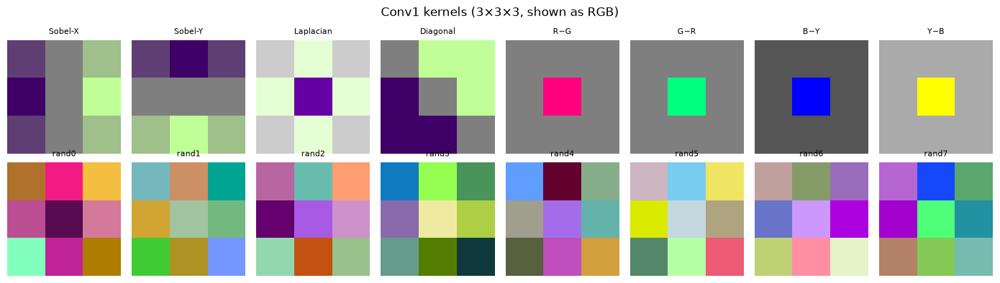

In [83]:
w = rgb_model.conv1.weight.detach().numpy()          # (16,3,3,3)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    k = w[i].transpose(1, 2, 0); k = (k - k.min()) / (k.max() - k.min() + 1e-8)
    ax.imshow(k, interpolation="nearest"); ax.set_title(conv1_names[i], fontsize=8); ax.axis("off")
plt.suptitle("Conv1 kernels (3×3×3, shown as RGB)"); plt.tight_layout(); plt.show()

**Inference:** 
- The first 8 kernels are designed: 4 edge kernels (gray/purple because they act equally on R, G, B through luminance) and 4 **colour-opponent** kernels shown as pure colours (R−G, G−R, B−Y, Y−B). 
- The last 8 are random colourful noise — untrained filters with no specific meaning.

## B.4 — Visualise every layer of the RGB CNN

**Question:** *Visualize:*
- *Output channels after each convolution layer.*
- *Pooling outputs.*
- *Flattened feature representation.*
- *Latent vector obtained before classification layer.*

In [84]:
handles = register_hooks(rgb_model)
with torch.no_grad():
    rgb_logits = rgb_model(rgb_tensor)
for h in handles: h.remove()
ract = rgb_model.activations
for k, v in ract.items():
    print(f"{k:<12} -> {tuple(v.shape)}")

conv1        -> (1, 16, 128, 128)
relu1        -> (1, 16, 128, 128)
pool1        -> (1, 16, 64, 64)
conv2        -> (1, 32, 64, 64)
relu2        -> (1, 32, 64, 64)
pool2        -> (1, 32, 32, 32)
conv3        -> (1, 64, 32, 32)
relu3        -> (1, 64, 32, 32)
pool3        -> (1, 64, 16, 16)
conv4        -> (1, 128, 16, 16)
relu4        -> (1, 128, 16, 16)
pool4        -> (1, 128, 8, 8)
flatten      -> (1, 8192)
fc_latent    -> (1, 256)
relu_latent  -> (1, 256)
classifier   -> (1, 10)


### Block 1 (edges / colour) — output channels after Conv1, then MaxPool1

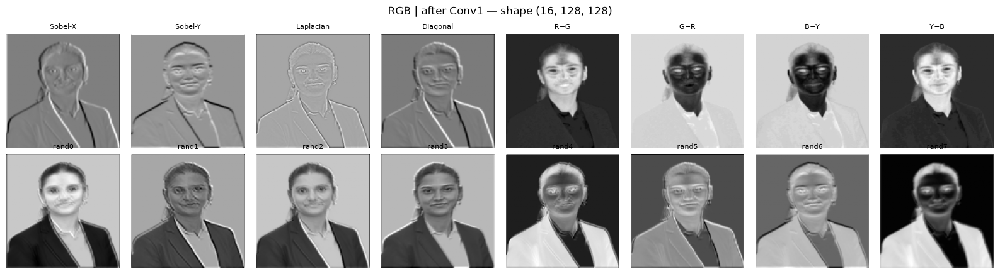

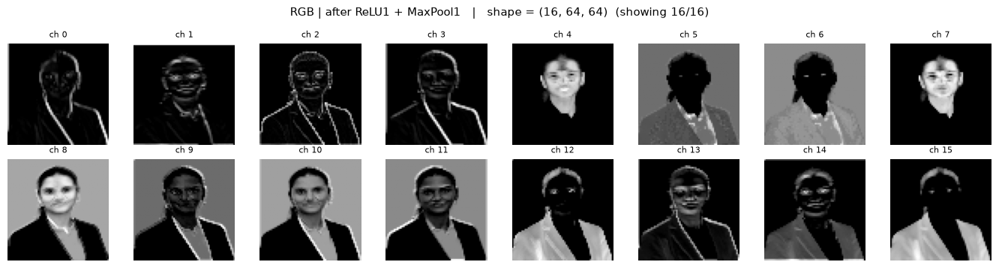

In [85]:
fmap = ract["conv1"][0].numpy()
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(fmap[i], cmap="gray"); ax.set_title(conv1_names[i], fontsize=8); ax.axis("off")
plt.suptitle(f"RGB | after Conv1 — shape {tuple(ract['conv1'].shape[1:])}"); plt.tight_layout(); plt.show()
show_feature_maps(ract["pool1"], "RGB | after ReLU1 + MaxPool1", cmap="gray")

**Inference:** 
- The edge channels outline the face, hair and blazer. 
- The colour-opponent channels separate regions by colour: **R−G** makes skin bright and the background neutral, **B−Y** does the opposite (background/shirt bright, skin dark). Random channels behave like mixed brightness/colour detectors. 
- After ReLU + MaxPool1, negative responses vanish and resolution halves to 64×64.

### Block 2 (textures) — Conv2 output channels, then MaxPool2

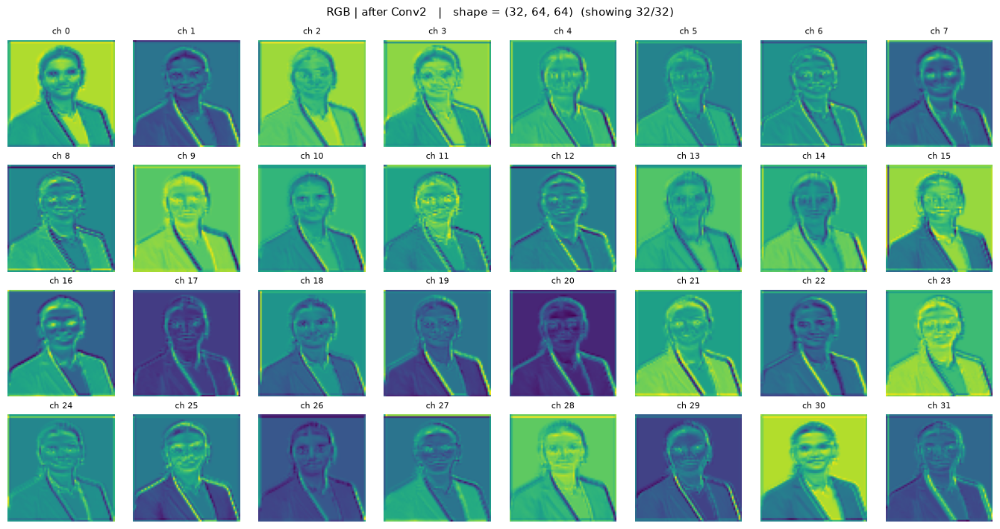

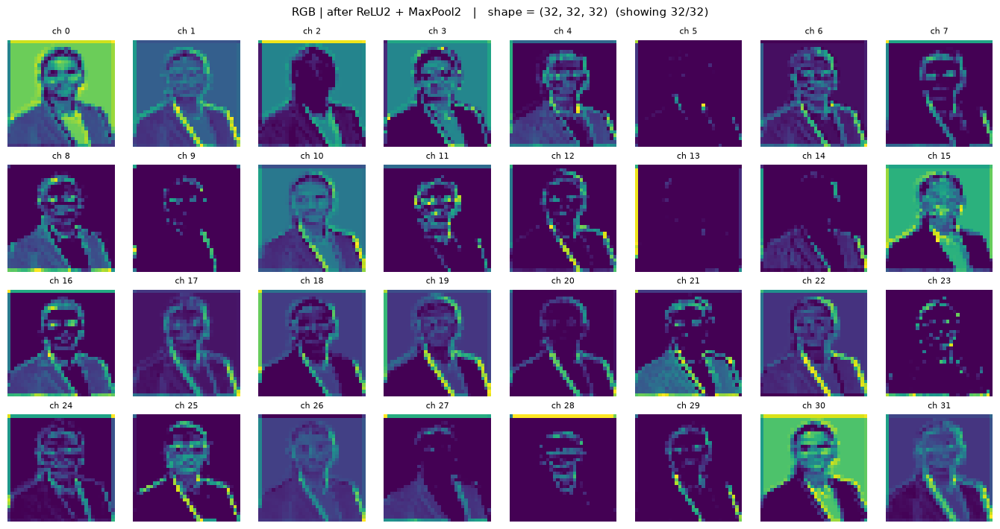

In [86]:
show_feature_maps(ract["conv2"], "RGB | after Conv2", max_maps=32)
show_feature_maps(ract["pool2"], "RGB | after ReLU2 + MaxPool2", max_maps=32)

**Inference:** 
- Conv2 channels combine the edge and colour maps: some highlight the face/skin region, others the blazer or the outline. 
- After ReLU and pooling (32×32), many channels keep only small parts of the image (e.g. just the face edges or just the collar) — the features become more **selective**, like early texture/part detectors.

### Block 3 (shapes / parts) — Conv3 output channels, then MaxPool3

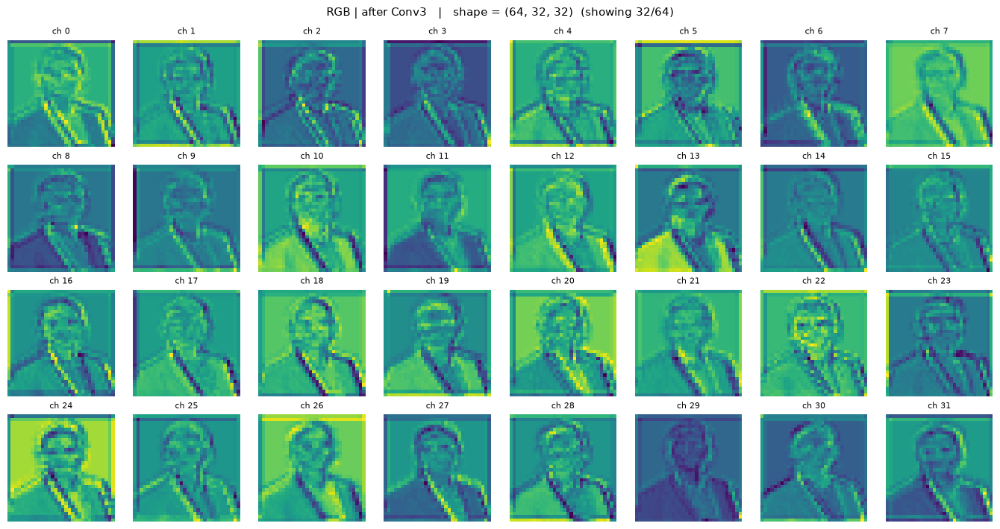

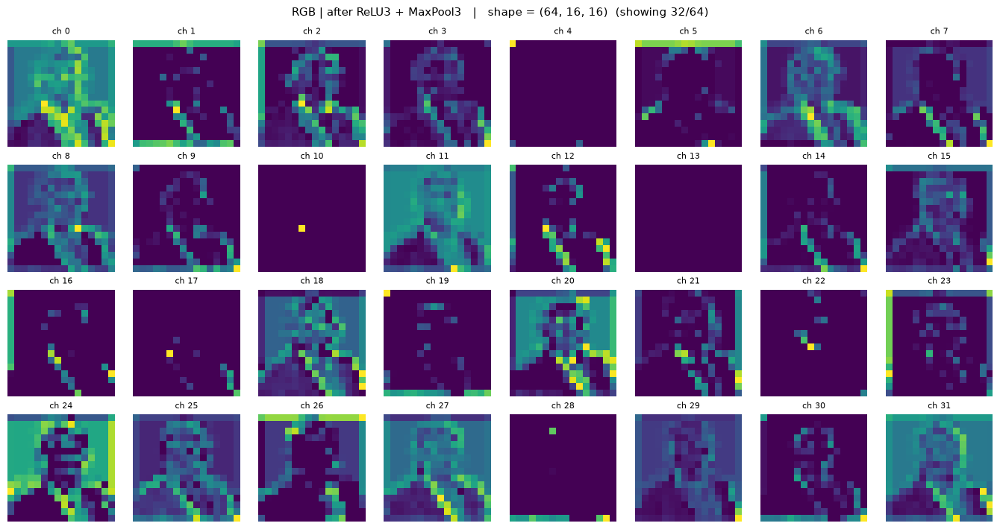

In [87]:
show_feature_maps(ract["conv3"], "RGB | after Conv3", max_maps=32)
show_feature_maps(ract["pool3"], "RGB | after ReLU3 + MaxPool3", max_maps=32)

**Inference:** 
- At 32×32 → 16×16, the person is still recognisable in Conv3 maps, but after pooling individual facial features dissolve into **blocks** marking regions such as the face, hair and blazer. 
- Several channels become almost entirely inactive — a sign of sparse, specialised (though untrained) detectors.

### Block 4 (high-level semantic) — Conv4 output channels, then MaxPool4

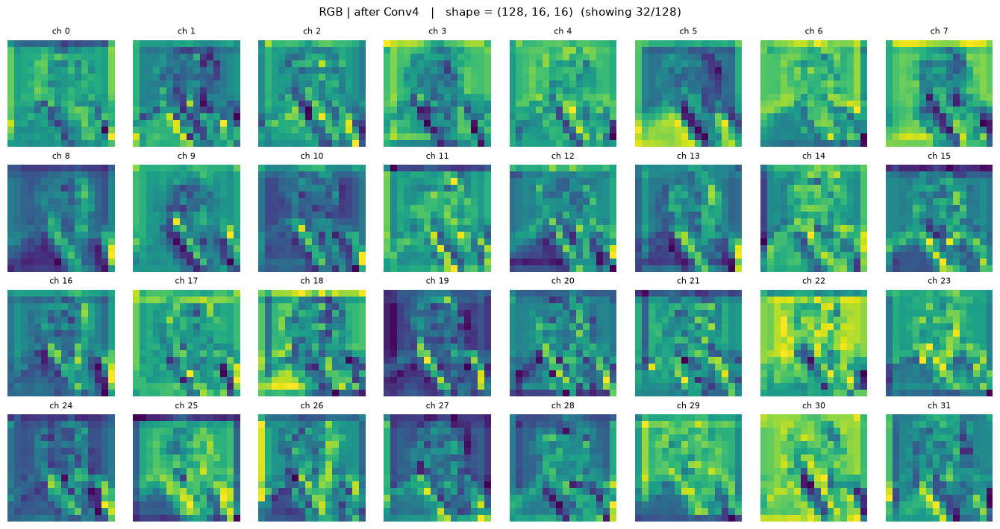

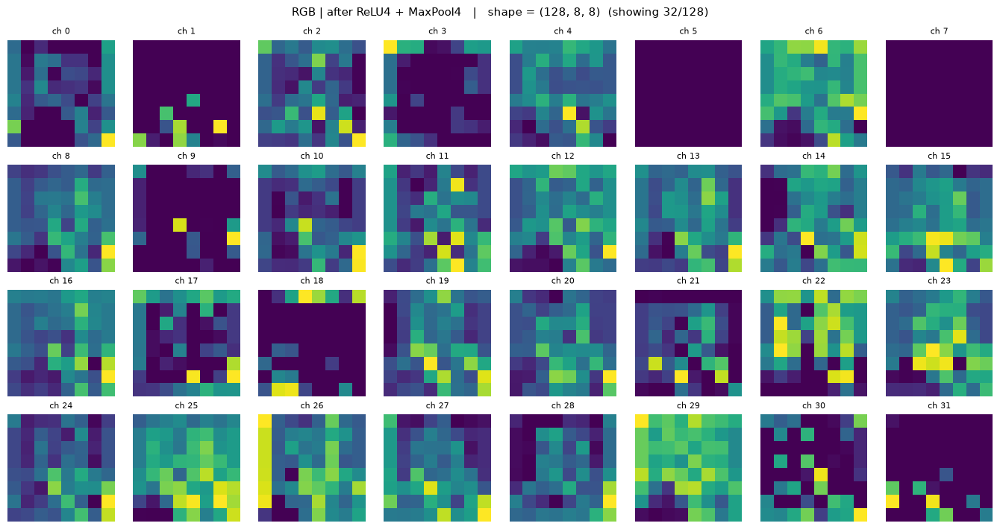

In [88]:
show_feature_maps(ract["conv4"], "RGB | after Conv4", max_maps=32)
show_feature_maps(ract["pool4"], "RGB | after ReLU4 + MaxPool4", max_maps=32)

**Inference:** 
- At 16×16 and 8×8 the maps are coarse grids of activations: they no longer show *what* the edges look like, only **where** certain combinations of features occur (roughly the head vs. body vs. background). 
- This is the level where, after training, channels would respond to high-level concepts such as "face" or "person".

### Flattened feature representation and latent vector (before the classification layer)

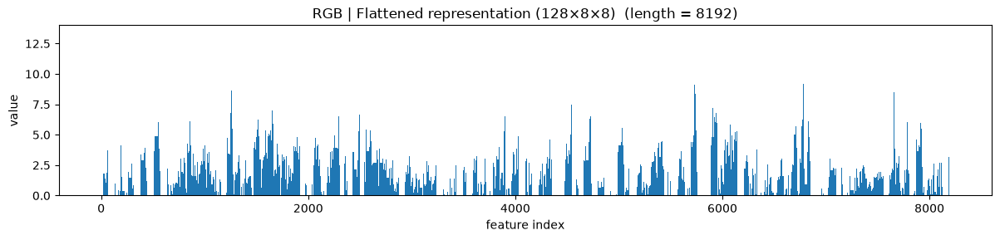

min=0.0000  max=13.3414  mean=1.6241  non-zero=5622/8192


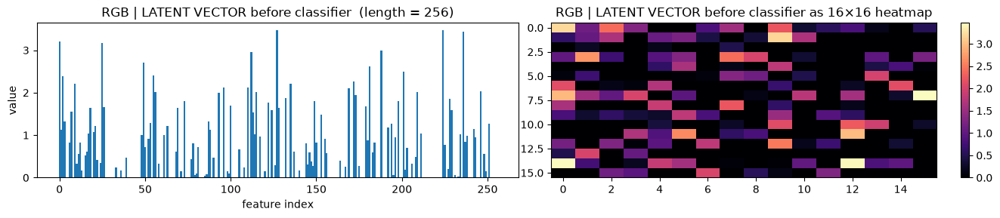

min=0.0000  max=3.4687  mean=0.5433  non-zero=122/256
Classifier output shape: (1, 10) (untrained scores)


In [89]:
show_vector(ract["flatten"], "RGB | Flattened representation (128×8×8)")
show_vector(ract["relu_latent"], "RGB | LATENT VECTOR before classifier", heat_cols=16)
print("Classifier output shape:", tuple(rgb_logits.shape), "(untrained scores)")

**Inference:** 
- The 128×8×8 pooled output flattens to **8,192** values, about 70% of them non-zero. 
- The dense layer compresses this into the **256-D latent vector** taken *before* the classifier, which is about half active. 
- This latent vector is the compact representation that a trained classifier would use to predict the class.


# PART C — Comparison: how a CNN extracts different levels of features

**Question:** *A comparison showing how CNN extracts different levels of features.*

In [90]:
def receptive_fields(model):
    rf, jump, out = 1, 1, {}
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d)):
            k = m.kernel_size if isinstance(m.kernel_size, int) else m.kernel_size[0]
            s = m.stride if isinstance(m.stride, int) else m.stride[0]
            rf += (k - 1) * jump; jump *= s
            out[name] = rf
    return out

rf = receptive_fields(rgb_model)
levels = [("conv1", "Edges / colour"), ("conv2", "Textures"), ("conv3", "Shapes / parts"), ("conv4", "High-level semantic")]

print(f"{'Layer':<8}{'Level':<22}{'Output shape':<18}{'RF (px)':>8}{'% active':>10}{'mean act':>10}")
print("-" * 76)
for l, lvl in levels:
    a = F.relu(ract[l])[0]
    print(f"{l:<8}{lvl:<22}{str(tuple(a.shape)):<18}{rf[l]:>8}{(a > 0).float().mean().item()*100:>9.1f}%{a.mean().item():>10.3f}")
print(f"{'latent':<8}{'Global descriptor':<22}{str(tuple(ract['relu_latent'].shape[1:])):<18}{'whole':>8}"
      f"{(ract['relu_latent'] > 0).float().mean().item()*100:>9.1f}%{ract['relu_latent'].mean().item():>10.3f}")

Layer   Level                 Output shape       RF (px)  % active  mean act
----------------------------------------------------------------------------
conv1   Edges / colour        (16, 128, 128)           3     50.2%     0.612
conv2   Textures              (32, 64, 64)             8     45.9%     0.798
conv3   Shapes / parts        (64, 32, 32)            18     42.3%     0.734
conv4   High-level semantic   (128, 16, 16)           38     52.0%     1.014
latent  Global descriptor     (256,)               whole     47.7%     0.543


**Inference:** 
- With depth, the output shape goes 128×128×16 → 64×64×32 → 32×32×64 → 16×16×128 (resolution ÷2, channels ×2 each block), and the **receptive field grows 3 → 8 → 18 → 38 px**, so each deep neuron "sees" a much larger part of the image. 
- About 40–50% of units are active at every level — ReLU keeps the representation sparse throughout.

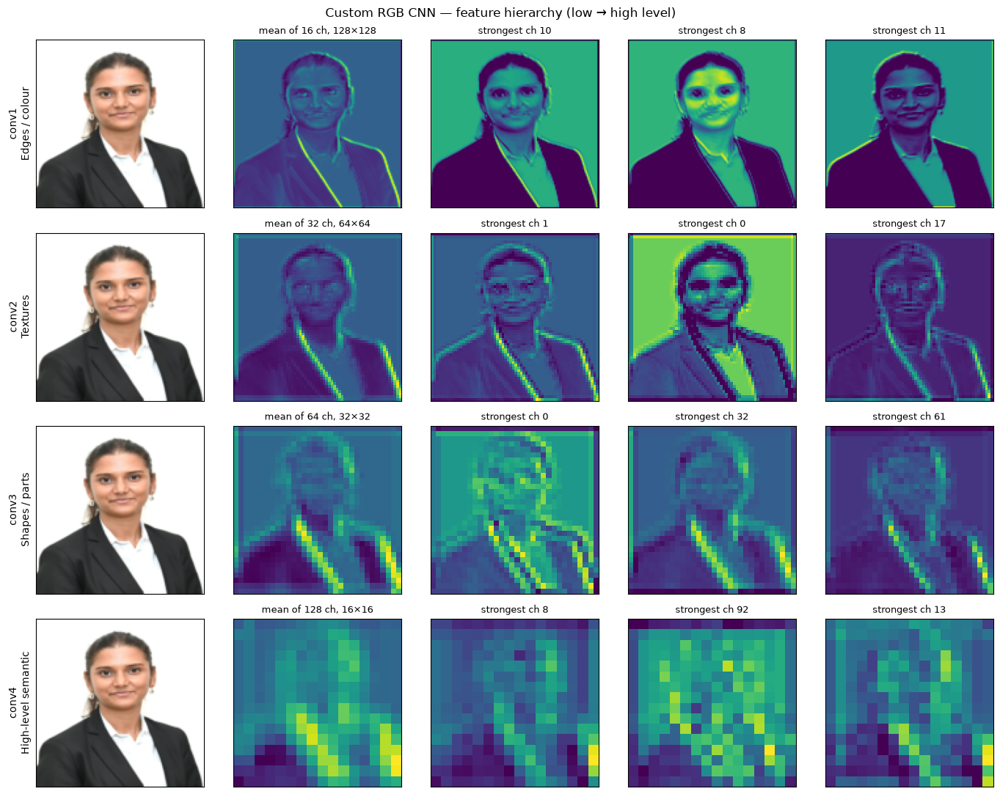

In [91]:
# Visual comparison: one row per feature level (custom RGB CNN)
fig, axes = plt.subplots(len(levels), 5, figsize=(14, 11))
for r, (l, lvl) in enumerate(levels):
    a = F.relu(ract[l])[0]
    top = a.mean((1, 2)).argsort(descending=True)[:3]
    axes[r, 0].imshow(rgb_01); axes[r, 0].set_ylabel(f"{l}\n{lvl}", fontsize=10)
    axes[r, 1].imshow(a.mean(0), cmap="viridis"); axes[r, 1].set_title(f"mean of {a.shape[0]} ch, {a.shape[1]}×{a.shape[2]}", fontsize=9)
    for c, ch in enumerate(top):
        axes[r, c + 2].imshow(a[ch], cmap="viridis"); axes[r, c + 2].set_title(f"strongest ch {ch.item()}", fontsize=9)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Custom RGB CNN — feature hierarchy (low → high level)"); plt.tight_layout(); plt.show()

**Inference:** 
- Reading the figure top to bottom: **Conv1** maps are sharp, full-resolution copies of the portrait's edges and colour regions; **Conv2** keeps outlines but starts to separate regions; **Conv3** becomes blocky, marking face/hair/blazer areas; **Conv4** is a coarse 16×16 grid that only indicates *where* strong feature combinations are. 
- Detail decreases while each unit summarises a larger area — this is the low → high level feature hierarchy.

### Comparison table

| Aspect | Low level (Conv1) | Mid level (Conv2–Conv3) | High level (Conv4) | Latent vector |
|---|---|---|---|---|
| Detects | edges, colour contrasts | textures, corners, simple shapes | object parts / semantic regions | compact global description |
| Receptive field | 3 px | 8 – 18 px | 38 px | whole image |
| Spatial resolution | high (128×128) | medium (64 → 32) | low (16×16) | none (vector) |
| Channels | 16 | 32 – 64 | 128 | 256 |
| Interpretability | high (can be hand-designed) | moderate | low per channel | used for classification / retrieval |
| Generic vs specific | generic — transfers to any image | partly generic | task specific (after training) | task specific |

### Grayscale vs RGB pipeline

| | Grayscale (X-ray) | RGB (portrait) |
|---|---|---|
| Input tensor | (1, 1, 128, 128) | (1, 3, 128, 128) |
| Conv1 kernel shape | (8, **1**, 3, 3) | (16, **3**, 3, 3) — each kernel spans all 3 colour channels |
| Normalisation | min-max to [0,1] | [0,1] + per-channel mean/std |
| Extra information | intensity only | intensity + colour (colour-opponent filters) |
| Depth | 3 conv blocks | 4 conv blocks |
| Latent size | 128 | 256 |

**Inference:** 
- Both pipelines follow the same Conv → ReLU → Pool pattern. 
- The RGB network needs 3-channel kernels and an extra block because colour images carry more information, and a deeper network gives a larger receptive field for higher-level features.

# PART D — Complexity / Self-learning component

**Question 1:** *Show convolution function as user defined and as inbuilt function.*
**Question 2:** *Number of filters in convolution layers.*

## D.1 — User-defined vs built-in convolution (correctness + speed)

Size       User-defined (ms)   Built-in (ms)    Speed-up
32x32                   3.31           0.037         89×
64x64                  14.39           0.126        114×
96x96                  30.66           0.145        211×
128x128                 52.60           0.078        672×


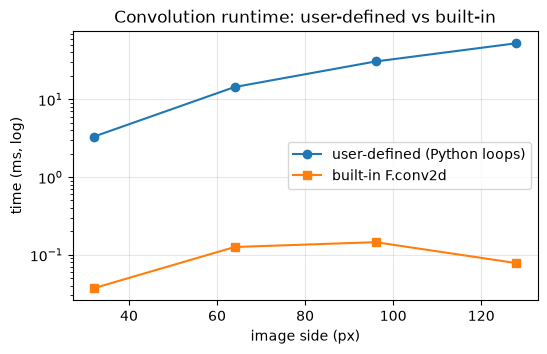

In [92]:
sizes = [32, 64, 96, 128]
k = gray_filters["Sobel-X (vertical edges)"]
t_u, t_b = [], []
for s in sizes:
    im = np.random.rand(s, s).astype(np.float32)
    t0 = time.perf_counter(); r_u = conv2d_user(im, k, padding=1); t_u.append(time.perf_counter() - t0)
    ti = torch.from_numpy(im)[None, None]; tk = torch.from_numpy(k)[None, None]
    t0 = time.perf_counter(); r_b = F.conv2d(ti, tk, padding=1); t_b.append(time.perf_counter() - t0)
    assert np.allclose(r_u, r_b[0, 0].numpy(), atol=1e-5)

print(f"{'Size':<8}{'User-defined (ms)':>20}{'Built-in (ms)':>16}{'Speed-up':>12}")
for s, a, b in zip(sizes, t_u, t_b):
    print(f"{s}x{s:<5}{a*1000:>20.2f}{b*1000:>16.3f}{a/b:>11.0f}×")

plt.figure(figsize=(6, 3.5))
plt.plot(sizes, np.array(t_u) * 1000, "o-", label="user-defined (Python loops)")
plt.plot(sizes, np.array(t_b) * 1000, "s-", label="built-in F.conv2d")
plt.yscale("log"); plt.xlabel("image side (px)"); plt.ylabel("time (ms, log)")
plt.title("Convolution runtime: user-defined vs built-in"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Inference:** Both implementations give identical results (checked with `assert`). The user-defined version's time grows roughly with the number of pixels (≈ 4 ms → 60 ms from 32² to 128²), while the built-in stays almost constant (< 0.1 ms), so the speed-up rises from tens to **several hundred times** as the image grows.

| | User-defined `conv2d_user` | Built-in `F.conv2d` / `nn.Conv2d` |
|---|---|---|
| Implementation | explicit sliding window with loops | vectorised C++/CUDA (im2col + GEMM, cuDNN) |
| Output | identical (≈1e-6 difference) | identical |
| Speed | slow — O(H·W·C·k²) Python operations | 100× – 10,000× faster |
| Learnable weights / gradients | no (fixed kernels) | yes — weights are `nn.Parameter`, trained by back-prop |
| Use | understanding / teaching | real models |

## D.2 — Effect of the number of filters in the convolution layers

We build `GrayMedCNN` with base filter counts **f ∈ {4, 8, 16, 32}** (layers use f, 2f, 4f) and measure parameters, flattened size, forward time and feature diversity.

In [93]:
results = []
for f in [4, 8, 16, 32]:
    torch.manual_seed(0)
    m = GrayMedCNN(f1=f, f2=2 * f, f3=4 * f).eval()
    conv_p = sum(p.numel() for n, p in m.named_parameters() if n.startswith("conv"))
    tot_p  = sum(p.numel() for p in m.parameters())
    hs = register_hooks(m)
    with torch.no_grad():
        t0 = time.perf_counter()
        for _ in range(10): m(gray_tensor)
        t = (time.perf_counter() - t0) / 10
    for h in hs: h.remove()
    a1 = m.activations["relu1"][0].flatten(1)                      # (f, H*W)
    corr = torch.corrcoef(a1)                                     # redundancy between Conv1 maps
    redundancy = corr[~torch.eye(f, dtype=bool)].abs().nanmean().item()
    results.append(dict(f=f, conv_params=conv_p, total=tot_p, flat=m.activations["flatten"].shape[1],
                        time_ms=t * 1000, redundancy=redundancy, act=m.activations))

print(f"{'filters (c1,c2,c3)':<20}{'conv params':>12}{'flatten dim':>13}{'total params':>14}{'fwd ms':>9}{'Conv1 redundancy':>18}")
for r in results:
    f = r["f"]
    print(f"{f'({f},{2*f},{4*f})':<20}{r['conv_params']:>12,}{r['flat']:>13,}{r['total']:>14,}{r['time_ms']:>9.2f}{r['redundancy']:>18.3f}")

filters (c1,c2,c3)   conv params  flatten dim  total params   fwd ms  Conv1 redundancy
(4,8,16)                   1,504        4,096       526,178     0.46             0.466
(8,16,32)                  5,888        8,192     1,054,850     0.79             0.421
(16,32,64)                23,296       16,384     2,120,834     1.47             0.367
(32,64,128)               92,672       32,768     4,287,362     3.24             0.311


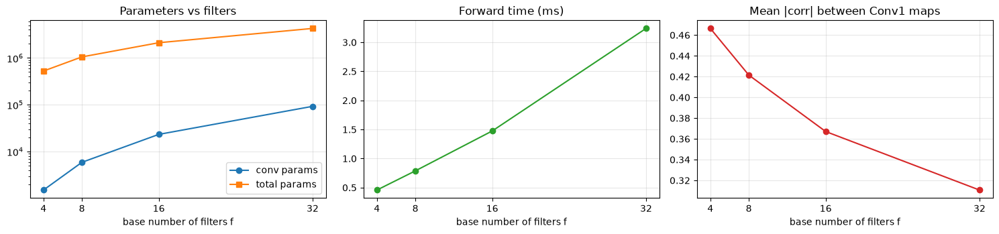

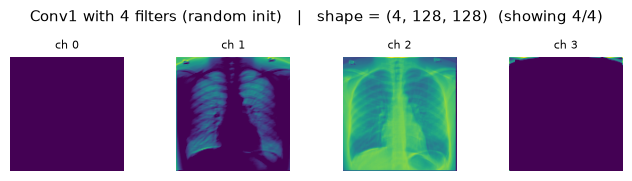

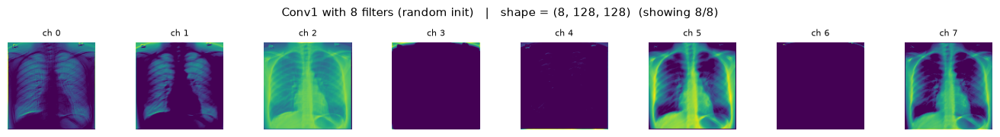

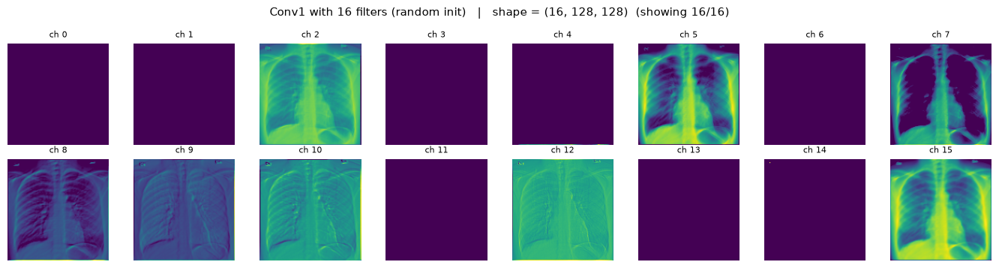

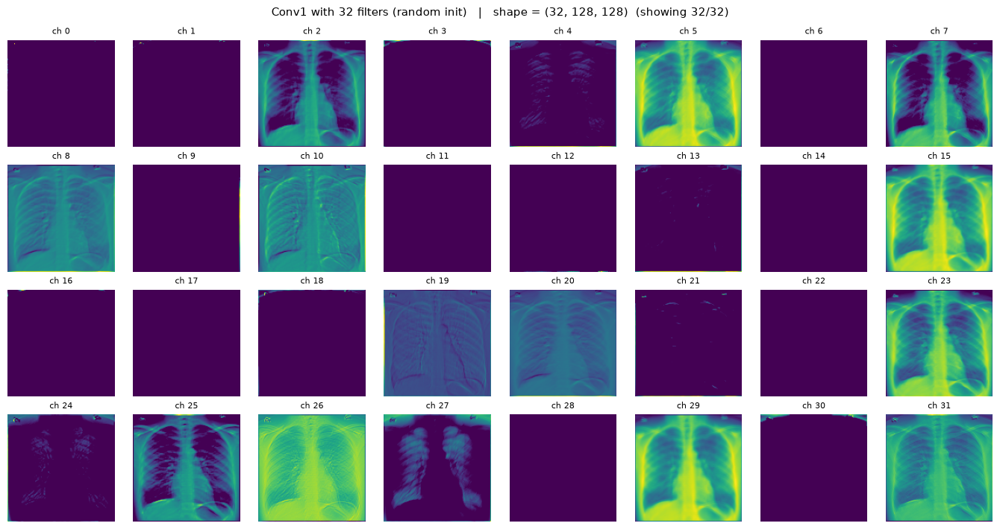

In [94]:
fs = [r["f"] for r in results]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(fs, [r["conv_params"] for r in results], "o-", label="conv params")
ax[0].plot(fs, [r["total"] for r in results], "s-", label="total params")
ax[0].set_yscale("log"); ax[0].set_title("Parameters vs filters"); ax[0].legend()
ax[1].plot(fs, [r["time_ms"] for r in results], "o-", color="C2"); ax[1].set_title("Forward time (ms)")
ax[2].plot(fs, [r["redundancy"] for r in results], "o-", color="C3"); ax[2].set_title("Mean |corr| between Conv1 maps")
for a in ax: a.set_xlabel("base number of filters f"); a.set_xticks(fs); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

for r in results:
    show_feature_maps(r["act"]["relu1"], f"Conv1 with {r['f']} filters (random init)", max_maps=r["f"], cols=min(8, r["f"]))

**Inference — number of filters:**
- Conv parameters grow roughly **quadratically** with f (each layer is ≈ $f_{in}\cdot f_{out}\cdot k^2$), and the flatten/dense size grows **linearly** — the dense layer dominates the total parameter count.
- More filters = **more distinct feature detectors** per layer. In our run the mean |correlation| between Conv1 maps fell from ≈ 0.47 (4 filters) to ≈ 0.31 (32 filters), i.e. the extra filters capture more *different* patterns. The feature-map grids confirm this: with 4 filters only 2 maps are useful, with 32 there is much more variety, but several maps are also dead (all zero after ReLU).
- Forward time grew ≈ 5× (0.8 → 3.8 ms) from 4 to 32 base filters.
- More filters cost more compute and memory and, with little data (e.g. small medical datasets), **increase over-fitting risk**. The common design — few filters early, doubling after each pooling — balances this.

## D.3 — Effect of other hyperparameters (kernel size, stride, padding, pooling type)

**Question (Aim):** *Analyse the effect of different hyperparameters.*

In [95]:
# Output-size formula check: O = floor((I - K + 2P)/S) + 1
I = IMG_SIZE
print(f"{'kernel':>7}{'stride':>8}{'padding':>9}{'formula O':>11}{'actual O':>10}")
for K_, S_, P_ in [(3, 1, 0), (3, 1, 1), (5, 1, 2), (7, 1, 3), (3, 2, 1), (5, 2, 0), (7, 3, 0)]:
    O = (I - K_ + 2 * P_) // S_ + 1
    actual = nn.Conv2d(1, 1, K_, stride=S_, padding=P_)(gray_tensor).shape[-1]
    print(f"{K_:>7}{S_:>8}{P_:>9}{O:>11}{actual:>10}")

 kernel  stride  padding  formula O  actual O
      3       1        0        126       126
      3       1        1        128       128
      5       1        2        128       128
      7       1        3        128       128
      3       2        1         64        64
      5       2        0         62        62
      7       3        0         41        41


**Inference:** For every combination the formula O = ⌊(I − K + 2P)/S⌋ + 1 matches PyTorch's actual output. Padding P = K//2 with stride 1 keeps the size at 128 ("same" padding); no padding shrinks it (126), and stride 2 or 3 roughly halves or thirds it.

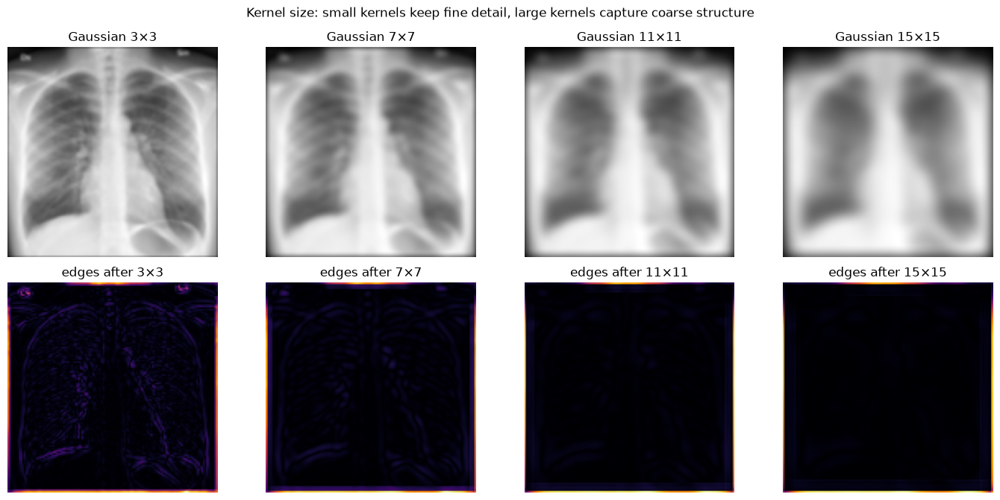

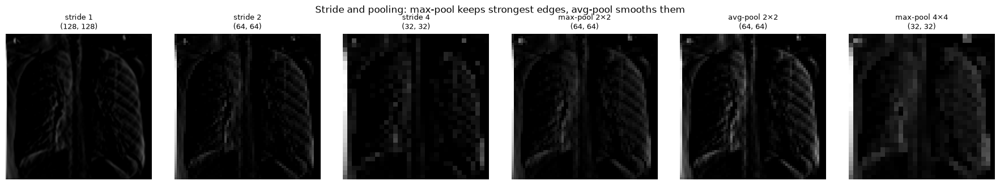

In [96]:
# Kernel size: a Gaussian blur of increasing size (larger kernel = larger receptive field, coarser features)
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
for c, k_ in enumerate([3, 7, 11, 15]):
    g = torch.from_numpy(gaussian_kernel(k_, k_ / 4))[None, None]
    blurred = F.conv2d(gray_tensor, g, padding=k_ // 2)
    lap = F.conv2d(blurred, torch.tensor([[[[0., 1, 0], [1, -4, 1], [0, 1, 0]]]]), padding=1)
    axes[0, c].imshow(blurred[0, 0], cmap="gray"); axes[0, c].set_title(f"Gaussian {k_}×{k_}")
    axes[1, c].imshow(lap[0, 0].abs(), cmap="inferno"); axes[1, c].set_title(f"edges after {k_}×{k_}")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Kernel size: small kernels keep fine detail, large kernels capture coarse structure"); plt.tight_layout(); plt.show()

# Stride and pooling type
sob = torch.tensor(gray_filters["Sobel-X (vertical edges)"])[None, None]
outs = {
    "stride 1": F.relu(F.conv2d(gray_tensor, sob, padding=1, stride=1)),
    "stride 2": F.relu(F.conv2d(gray_tensor, sob, padding=1, stride=2)),
    "stride 4": F.relu(F.conv2d(gray_tensor, sob, padding=1, stride=4)),
}
base = outs["stride 1"]
outs["max-pool 2×2"] = F.max_pool2d(base, 2)
outs["avg-pool 2×2"] = F.avg_pool2d(base, 2)
outs["max-pool 4×4"] = F.max_pool2d(base, 4)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.3))
for ax, (n, o) in zip(axes, outs.items()):
    ax.imshow(o[0, 0], cmap="gray"); ax.set_title(f"{n}\n{tuple(o.shape[-2:])}", fontsize=9); ax.axis("off")
plt.suptitle("Stride and pooling: max-pool keeps strongest edges, avg-pool smooths them"); plt.tight_layout(); plt.show()

**Inference:** 
- Stride 2 and 4 shrink the map to 64² and 32² but look grainy — they simply skip pixels, so thin rib edges can vanish. 
- **Max-pool 2×2** keeps the edges bright and continuous; **avg-pool 2×2** keeps them but slightly dimmer and smoother; max-pool 4×4 keeps the main structure (rib-cage outline, spine) even at 32×32. 
- Pooling down-samples more gracefully than a large stride.

**Inference:** 
- As the Gaussian kernel grows from 3×3 to 15×15, the X-ray gets progressively blurrier — ribs disappear first, then only the lung/heart silhouette remains. 
- The edge maps below become darker and fainter, meaning fine edges are lost and only coarse boundaries survive. 
- **Larger kernels = larger receptive field = coarser features.**
- A dark/bright line at the border is again a padding artefact.

activation        % exactly zero      min      max
none (linear)               0.4%    -3.79     3.33
ReLU                       25.4%     0.00     3.33
LeakyReLU(0.1)              0.4%    -0.38     3.33
Sigmoid                     0.0%     0.02     0.97
Tanh                        0.4%    -1.00     1.00


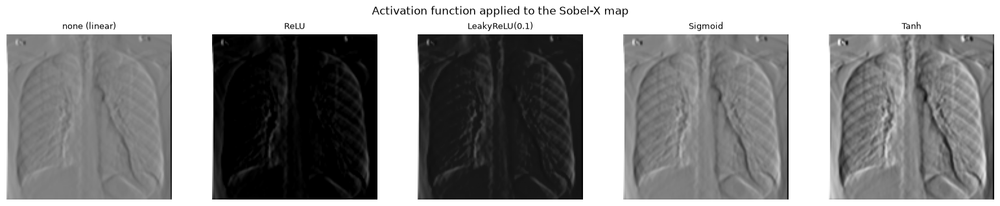

In [97]:
# Activation function: effect on sparsity of Conv1 maps
pre = gact["conv1"]
acts = {"none (linear)": pre, "ReLU": F.relu(pre), "LeakyReLU(0.1)": F.leaky_relu(pre, 0.1),
        "Sigmoid": torch.sigmoid(pre), "Tanh": torch.tanh(pre)}
print(f"{'activation':<16}{'% exactly zero':>16}{'min':>9}{'max':>9}")
for n, a in acts.items():
    print(f"{n:<16}{(a == 0).float().mean().item()*100:>15.1f}%{a.min().item():>9.2f}{a.max().item():>9.2f}")
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, (n, a) in zip(axes, acts.items()):
    ax.imshow(a[0, 0], cmap="gray"); ax.set_title(n, fontsize=9); ax.axis("off")
plt.suptitle("Activation function applied to the Sobel-X map"); plt.tight_layout(); plt.show()

**Inference:** Without an activation the map keeps positive and negative edges (gray background). **ReLU** sets ≈ 25% of the values to exactly 0 and keeps only positive edges → a sparse map. **LeakyReLU** keeps a faint trace of negative edges. **Sigmoid** squashes everything into (0, 1) and **tanh** into (−1, 1) — they look like embossed images with no exact zeros and saturate at large values.

**Inference — hyperparameters:**

| Hyperparameter | Effect |
|---|---|
| **Number of filters** | more feature types, more parameters/compute, higher over-fitting risk |
| **Kernel size** | larger kernel → larger receptive field and coarser features, $k^2$ more weights; stacking 3×3 kernels is cheaper for the same receptive field |
| **Stride** | stride $s$ divides the output size by ≈ $s$; faster, but can skip fine details (aliasing) |
| **Padding** | `padding = k//2` ("same") keeps the spatial size and preserves border information |
| **Pooling type** | max-pool keeps the strongest response (good for edges/presence); average-pool smooths and keeps overall intensity |
| **Activation** | ReLU zeros all negative responses (≈25% of this map) → sparse, efficient features; sigmoid/tanh saturate and keep no exact zeros |


# PART E — Conclusions

1. **Pre-processing** (resize → normalise → NCHW tensor) turns an arbitrary image into the fixed-size, well-scaled input that a CNN requires. The grayscale X-ray gives 1 input channel; the RGB portrait gives 3, normalised per channel.
2. **Convolution** was implemented both **from scratch** and with **PyTorch's built-in** `F.conv2d` / `nn.Conv2d`; the outputs are identical, but the built-in version is hundreds of times faster and its weights are learnable.
3. **Hand-crafted filters** extract **edges** (Sobel, Laplacian), **textures** (Gabor) and **shapes/blobs** (LoG, DoG). **High-level semantic features** cannot be hand-designed; they emerge only in deep, trained layers.
4. Through the network, **resolution decreases while channels and receptive field increase** (3 → 38 px), and features move from local/generic to global/specific. Pooling provides down-sampling and shift tolerance; ReLU makes activations sparse.
5. The **flatten + dense layer** compresses thousands of activations into a **latent vector** (128-D for the X-ray, 256-D for the RGB image), which is the representation fed to the classification layer.
6. **Number of filters** controls representational capacity vs. cost: conv parameters grow ~quadratically and compute time increases; more filters give more diverse features but raise over-fitting risk on small (medical) datasets.


# Final Summary

| Item | Grayscale medical image | RGB image |
|---|---|---|
| Image | Chest X-ray (PA view) | Portrait photograph |
| Pre-processing | Resize 128×128 → min-max [0,1] → tensor (1,1,128,128) | Resize 128×128 → [0,1] → per-channel normalise → tensor (1,3,128,128) |
| User-defined filters | 8 (Sobel-X/Y, Laplacian, Prewitt, sharpen, blur, emboss, box) | 12 (4 edge, 4 Gabor texture, 4 shape) + 8 designed Conv1 kernels |
| Architecture | `GrayMedCNN`: 3 × (Conv3×3 → ReLU → MaxPool), filters 8-16-32 → Flatten (8,192) → Dense 128 | `RGBFeatureCNN`: 4 × (Conv3×3 → ReLU → MaxPool), filters 16-32-64-128 → Flatten (8,192) → Dense 256 |
| Latent vector | 128-D | 256-D (before classifier) |
| Key observation | Conv1 shows ribs/heart/diaphragm edges; deeper layers show coarse lung and mediastinum regions | Conv1 shows face/blazer edges and colour regions; deeper layers show coarse face/body/background regions |

**SUMMARY:** 
- A CNN turns an image into a hierarchy of feature maps — **edges → textures → shapes/parts → semantic regions** — and finally into a compact **latent vector**. 
- User-defined and built-in convolution produce the same features, but built-in layers are far faster and trainable. 
- Hyperparameters such as the number of filters, kernel size, stride, pooling and activation control how much detail is kept, how large an area each feature covers, and how many parameters the model needs.

# PART B — LeNet-5 Architecture on MNIST and Hyperparameter Tuning

In [98]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
import torchvision.transforms as T
import pandas as pd
import matplotlib.pyplot as plt
import time
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
import pandas as pd
import itertools
import copy

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


### Cell 3 — MNIST dataset

In [99]:
transform = T.Compose([
    T.Pad(2),
    T.ToTensor(),
    T.Normalize((0.1307,), (0.3081,))
])

train_dataset_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split training data into training and validation sets
train_size = int(0.9 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

train_dataset, val_dataset = random_split(
    train_dataset_full,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples  :", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples      :", len(test_dataset))

Training samples  : 54000
Validation samples: 6000
Test samples      : 10000


### Visualize MNIST samples

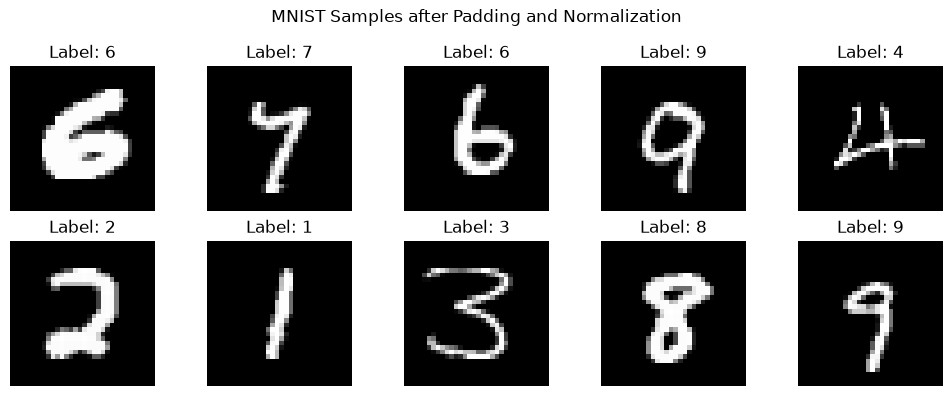

In [100]:
# Display some MNIST samples after preprocessing

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, (image, label) in zip(axes.ravel(), [train_dataset[i] for i in range(10)]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("MNIST Samples after Padding and Normalization")
plt.tight_layout()
plt.show()

**Inference:**  
The MNIST samples are correctly preprocessed and padded from 28×28 to 32×32 pixels to match the input requirement of LeNet-5. The handwritten digits remain clearly recognizable after padding and normalization, indicating that the preprocessing preserves the important visual information required for classification.

### LeNet-5 architecture

In [101]:
class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # C1: 1 input channel -> 6 feature maps
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=6,
            kernel_size=5
        )

        # S2: Average pooling
        self.pool1 = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        # C3: 6 -> 16 feature maps
        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        # S4: Average pooling
        self.pool2 = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        # C5: 16 -> 120 feature maps
        # Input after C3 + pooling = 5x5
        self.conv3 = nn.Conv2d(
            in_channels=16,
            out_channels=120,
            kernel_size=5
        )

        # Fully connected layers
        self.fc1 = nn.Linear(120, 84)
        self.fc2 = nn.Linear(84, num_classes)

        self.activation = nn.Tanh()

    def forward(self, x):

        # C1 -> Tanh -> S2
        x = self.activation(self.conv1(x))
        x = self.pool1(x)

        # C3 -> Tanh -> S4
        x = self.activation(self.conv2(x))
        x = self.pool2(x)

        # C5 -> Tanh
        x = self.activation(self.conv3(x))

        # Flatten
        x = torch.flatten(x, 1)

        # F6 -> Tanh
        x = self.activation(self.fc1(x))

        # Output layer
        x = self.fc2(x)

        return x

### Display architecture and parameter count.

In [102]:
model = LeNet5().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=10, bias=True)
  (activation): Tanh()
)

Total trainable parameters: 61706


### Verify tensor dimensions

In [103]:
# Verify the output shape at each stage

x = torch.randn(1, 1, 32, 32).to(device)

with torch.no_grad():
    x1 = model.activation(model.conv1(x))
    x2 = model.pool1(x1)
    x3 = model.activation(model.conv2(x2))
    x4 = model.pool2(x3)
    x5 = model.activation(model.conv3(x4))
    x6 = torch.flatten(x5, 1)
    x7 = model.activation(model.fc1(x6))
    x8 = model.fc2(x7)

print("Input       :", tuple(x.shape))
print("After C1    :", tuple(x1.shape))
print("After S2    :", tuple(x2.shape))
print("After C3    :", tuple(x3.shape))
print("After S4    :", tuple(x4.shape))
print("After C5    :", tuple(x5.shape))
print("Flattened   :", tuple(x6.shape))
print("After F6    :", tuple(x7.shape))
print("Output      :", tuple(x8.shape))

Input       : (1, 1, 32, 32)
After C1    : (1, 6, 28, 28)
After S2    : (1, 6, 14, 14)
After C3    : (1, 16, 10, 10)
After S4    : (1, 16, 5, 5)
After C5    : (1, 120, 1, 1)
Flattened   : (1, 120)
After F6    : (1, 84)
Output      : (1, 10)


**Inference:**  
The tensor dimensions decrease progressively through the convolution and average-pooling layers, while the number of feature maps increases. This allows LeNet-5 to transform the input image from low-level spatial information into increasingly compact feature representations before producing predictions for the 10 MNIST digit classes.

### Training and evaluation functions

In [104]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

### Function to train a complete configuration

In [105]:
def train_model(config, verbose=False):

    batch_size = config["batch_size"]
    learning_rate = config["learning_rate"]
    optimizer_name = config["optimizer"]
    epochs = config["epochs"]

    # DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    # New model for every configuration
    model = LeNet5().to(device)

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9
        )

    start_time = time.time()

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = 0.0

    for epoch in range(epochs):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        best_val_accuracy = max(
            best_val_accuracy,
            val_accuracy
        )

        if verbose:
            print(
                f"Epoch [{epoch+1}/{epochs}] "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_accuracy:.2f}% | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_accuracy:.2f}%"
            )

    training_time = time.time() - start_time

    return model, history, best_val_accuracy, training_time

### Hyperameter search

In [106]:
hyperparameter_configs = [
    {
        "batch_size": 64,
        "learning_rate": 0.001,
        "optimizer": "Adam",
        "epochs": 5
    },
    {
        "batch_size": 128,
        "learning_rate": 0.001,
        "optimizer": "Adam",
        "epochs": 5
    },
    {
        "batch_size": 64,
        "learning_rate": 0.0005,
        "optimizer": "Adam",
        "epochs": 5
    },
    {
        "batch_size": 128,
        "learning_rate": 0.0005,
        "optimizer": "Adam",
        "epochs": 5
    },
    {
        "batch_size": 64,
        "learning_rate": 0.01,
        "optimizer": "SGD",
        "epochs": 5
    },
    {
        "batch_size": 128,
        "learning_rate": 0.01,
        "optimizer": "SGD",
        "epochs": 5
    }
]

results = []
trained_models = {}
histories = {}

for i, config in enumerate(hyperparameter_configs, start=1):

    print("\n" + "=" * 70)
    print(f"Configuration {i}/{len(hyperparameter_configs)}")
    print(config)
    print("=" * 70)

    model, history, best_val_accuracy, training_time = train_model(
        config,
        verbose=False
    )

    results.append({
        "Configuration": i,
        "Batch Size": config["batch_size"],
        "Learning Rate": config["learning_rate"],
        "Optimizer": config["optimizer"],
        "Epochs": config["epochs"],
        "Best Validation Accuracy (%)": best_val_accuracy,
        "Training Time (sec)": training_time
    })

    trained_models[i] = model
    histories[i] = history

    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    print(
        f"Training Time: "
        f"{training_time:.2f} seconds"
    )


Configuration 1/6
{'batch_size': 64, 'learning_rate': 0.001, 'optimizer': 'Adam', 'epochs': 5}
Best Validation Accuracy: 98.52%
Training Time: 72.66 seconds

Configuration 2/6
{'batch_size': 128, 'learning_rate': 0.001, 'optimizer': 'Adam', 'epochs': 5}
Best Validation Accuracy: 98.30%
Training Time: 53.97 seconds

Configuration 3/6
{'batch_size': 64, 'learning_rate': 0.0005, 'optimizer': 'Adam', 'epochs': 5}
Best Validation Accuracy: 98.47%
Training Time: 72.67 seconds

Configuration 4/6
{'batch_size': 128, 'learning_rate': 0.0005, 'optimizer': 'Adam', 'epochs': 5}
Best Validation Accuracy: 98.45%
Training Time: 52.73 seconds

Configuration 5/6
{'batch_size': 64, 'learning_rate': 0.01, 'optimizer': 'SGD', 'epochs': 5}
Best Validation Accuracy: 98.48%
Training Time: 78.72 seconds

Configuration 6/6
{'batch_size': 128, 'learning_rate': 0.01, 'optimizer': 'SGD', 'epochs': 5}
Best Validation Accuracy: 98.10%
Training Time: 51.60 seconds


### Hyperparameter tuning results

In [107]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Best Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("Hyperparameter Tuning Results:")
display(results_df)

Hyperparameter Tuning Results:


,Configuration,Batch Size,Learning Rate,Optimizer,Epochs,Best Validation Accuracy (%),Training Time (sec)
0,1,64,0.0010,Adam,5,98.516667,72.663691
1,5,64,0.0100,SGD,5,98.483333,78.718284
2,3,64,0.0005,Adam,5,98.466667,72.669641
3,4,128,0.0005,Adam,5,98.450000,52.734234
4,2,128,0.0010,Adam,5,98.300000,53.971284
5,6,128,0.0100,SGD,5,98.100000,51.598174


**Inference:**  
The hyperparameter experiments show that all tested configurations achieve high validation accuracy above 98%. The best validation accuracy of 98.52% was obtained using the Adam optimizer with a learning rate of 0.001 and a batch size of 64. The lowest validation accuracy was 98.10% using SGD with a learning rate of 0.01 and a batch size of 128. Therefore, the tested hyperparameters influence performance, although the overall difference in validation accuracy is relatively small.

The results also show that increasing the batch size from 64 to 128 generally reduces training time. This indicates a trade-off between computational efficiency and classification performance.

### Viualize hyperparameter comparison

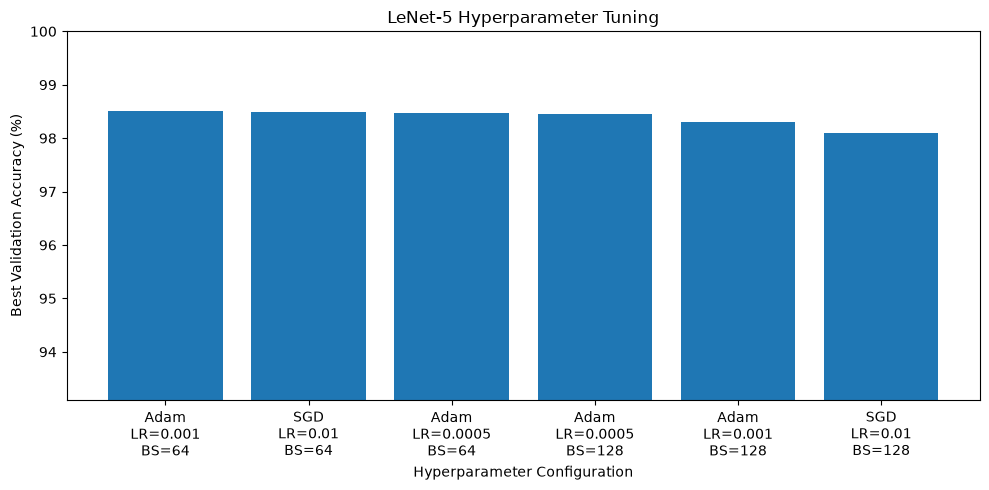

In [108]:
plt.figure(figsize=(10, 5))

labels = [
    f"{row['Optimizer']}\n"
    f"LR={row['Learning Rate']}\n"
    f"BS={row['Batch Size']}"
    for _, row in results_df.iterrows()
]

plt.bar(
    range(len(results_df)),
    results_df["Best Validation Accuracy (%)"]
)

plt.xticks(
    range(len(results_df)),
    labels,
    rotation=0
)

plt.ylabel("Best Validation Accuracy (%)")
plt.xlabel("Hyperparameter Configuration")
plt.title("LeNet-5 Hyperparameter Tuning")
plt.ylim(
    max(0, results_df["Best Validation Accuracy (%)"].min() - 5),
    100
)

plt.tight_layout()
plt.show()

**Inference:**  
The hyperparameter comparison graph shows that the validation accuracies of all six configurations are very close, remaining above 98%. Adam with a learning rate of 0.001 and batch size 64 achieves the highest validation accuracy of 98.52%, while SGD with a learning rate of 0.01 and batch size 128 achieves the lowest at 98.10%. The small difference between the configurations indicates that LeNet-5 performs robustly across the tested hyperparameter settings.

### Select best configuration

In [109]:
best_row = results_df.iloc[0]

best_config_id = int(best_row["Configuration"])

best_model = trained_models[best_config_id]
best_history = histories[best_config_id]

print("Best Hyperparameter Configuration")
print("-" * 40)
print("Batch Size     :", best_row["Batch Size"])
print("Learning Rate  :", best_row["Learning Rate"])
print("Optimizer      :", best_row["Optimizer"])
print("Epochs         :", best_row["Epochs"])
print(
    "Validation Acc :",
    f"{best_row['Best Validation Accuracy (%)']:.2f}%"
)

Best Hyperparameter Configuration
----------------------------------------
Batch Size     : 64
Learning Rate  : 0.001
Optimizer      : Adam
Epochs         : 5
Validation Acc : 98.52%


### Training curves for the best configuration

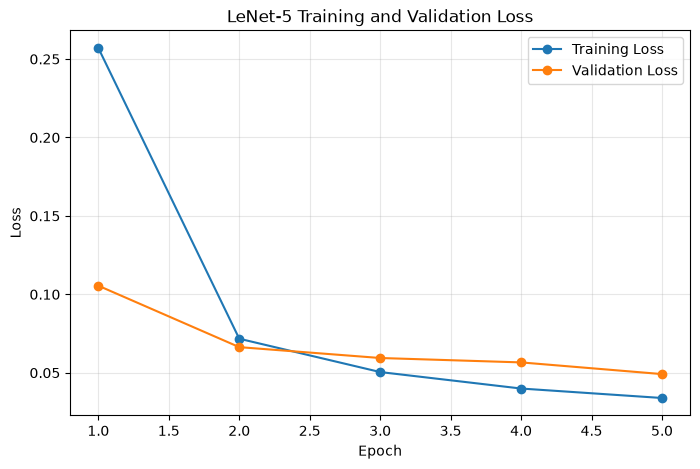

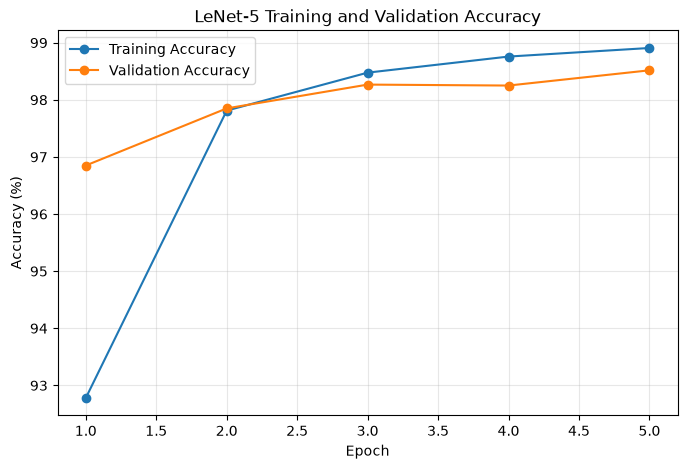

In [110]:
epochs_range = range(
    1,
    len(best_history["train_loss"]) + 1
)

# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    best_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    best_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet-5 Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Accuracy curve
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    best_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    best_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LeNet-5 Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Inference:**  
The training and validation loss decrease consistently across the five epochs, indicating that the LeNet-5 model is learning effectively and approaching convergence. The validation loss does not show a significant increase during training, suggesting that there is no severe overfitting within the observed epochs.

The training accuracy increases from approximately 92.8% to 98.9%, while the validation accuracy increases from approximately 96.8% to 98.5%. The small difference between the training and validation accuracy indicates good generalization. The gradual flattening of the curves toward the final epochs suggests that the model is approaching convergence.

### Test the best model

In [111]:
test_loader = DataLoader(
    test_dataset,
    batch_size=int(best_row["Batch Size"]),
    shuffle=False,
    num_workers=0
)

criterion = nn.CrossEntropyLoss()

test_loss, test_accuracy = evaluate(
    best_model,
    test_loader,
    criterion
)

print("Final Test Results")
print("-" * 40)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2f}%")

Final Test Results
----------------------------------------
Test Loss     : 0.0365
Test Accuracy : 98.81%


**Inference:**  
The selected LeNet-5 model achieves a test accuracy of 98.81% with a test loss of 0.0365 on the unseen MNIST test set. The test accuracy is slightly higher than the validation accuracy of 98.52%, indicating that the model generalizes well to unseen test samples.

### Confusion Matrix

<Figure size 800x800 with 0 Axes>

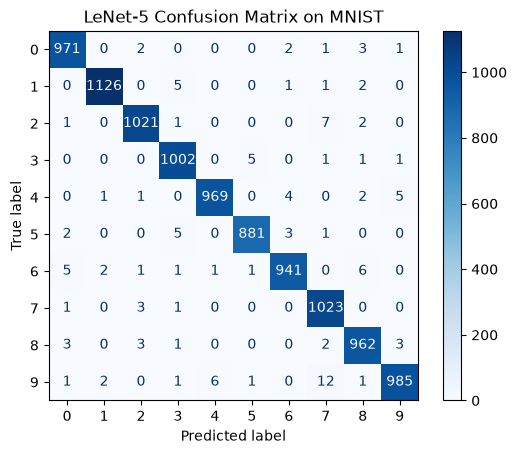

In [112]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = best_model(images)

        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(8, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("LeNet-5 Confusion Matrix on MNIST")
plt.show()

**Inference:**  
The confusion matrix shows that the majority of predictions lie along the diagonal, indicating that most handwritten digits are classified correctly. Only a small number of samples are misclassified. Some errors occur between visually similar handwritten digits, with the most noticeable confusion occurring between digits 9 and 7. Overall, the confusion matrix supports the high test accuracy of 98.81%.

### Display Predictions

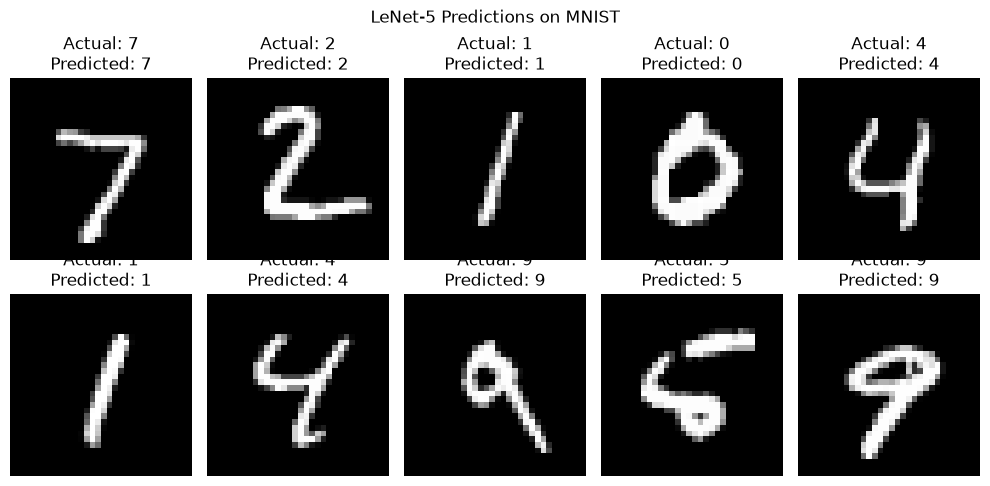

In [113]:
best_model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = best_model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):

    ax.imshow(
        images[i].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"Actual: {labels[i].item()}\n"
        f"Predicted: {predictions[i].item()}"
    )

    ax.axis("off")

plt.suptitle("LeNet-5 Predictions on MNIST")
plt.tight_layout()
plt.show()

**Inference:**  
The displayed test samples show that the predicted labels match the actual labels for the visualized examples. This provides qualitative evidence that the trained LeNet-5 model can correctly recognize different handwritten digit patterns.

### Final comparison table

In [114]:
final_summary = pd.DataFrame({
    "Model": ["LeNet-5"],
    "Dataset": ["MNIST"],
    "Input Size": ["32 × 32"],
    "Optimizer": [best_row["Optimizer"]],
    "Learning Rate": [best_row["Learning Rate"]],
    "Batch Size": [best_row["Batch Size"]],
    "Epochs": [best_row["Epochs"]],
    "Validation Accuracy (%)": [
        best_row["Best Validation Accuracy (%)"]
    ],
    "Test Accuracy (%)": [test_accuracy],
    "Trainable Parameters": [
        sum(
            p.numel()
            for p in best_model.parameters()
            if p.requires_grad
        )
    ]
})

display(final_summary)

,Model,Dataset,Input Size,Optimizer,Learning Rate,Batch Size,Epochs,Validation Accuracy (%),Test Accuracy (%),Trainable Parameters
0,LeNet-5,MNIST,32 × 32,Adam,0.001,64,5,98.516667,98.81,61706


**Observation:**  
The final results show that the selected LeNet-5 configuration uses the Adam optimizer with a learning rate of 0.001, batch size of 64 and 5 training epochs. It achieves a validation accuracy of 98.52% and a test accuracy of 98.81% with 61,706 trainable parameters.

#  Conclusion

- The **LeNet-5 architecture** was successfully implemented for handwritten digit classification using the **MNIST dataset**.

- Since MNIST images are originally **28×28 pixels**, they were padded to **32×32 pixels** to match the input configuration of the LeNet-5 architecture.

- The implemented network follows the classical LeNet-5 structure using **three convolutional layers, average-pooling layers, Tanh activation and fully connected layers**, with 10 output classes.

- The model contains **61,706 trainable parameters** and progressively reduces the spatial dimensions while increasing the number of learned feature maps.

- The training and validation curves show that the model converges effectively, with training accuracy reaching approximately **98.9%** and validation accuracy reaching approximately **98.5%** after five epochs.

- Hyperparameter tuning was performed by varying the **optimizer, learning rate and batch size** across six configurations. All configurations achieved validation accuracies above **98%**, with relatively small differences in classification performance.

- Among the tested configurations, **Adam with a learning rate of 0.001 and batch size 64** achieved the highest validation accuracy of **98.52%**.

- The selected model achieved a final **test accuracy of 98.81%** with a test loss of **0.0365**, demonstrating strong generalization on unseen MNIST samples.

- The confusion matrix shows that most predictions fall along the diagonal, with only a small number of misclassifications. The sample prediction visualization also demonstrates correct predictions for the displayed test images.

- The hyperparameter experiments indicate that **learning rate, optimizer and batch size influence model performance and computational time**. In the tested configurations, the effect on validation accuracy was relatively small, while larger batch sizes generally resulted in shorter training times.

- Overall, the experiment demonstrates that **LeNet-5 can effectively learn hierarchical features from handwritten digit images and achieve high classification accuracy on the MNIST dataset**.